# 머신러닝 과제 2: YOLOv8 fine-tuning — 반려동물 3개 부류(고양이·토끼·햄스터) 감지·추적

위에서부터 순서대로 실행하면 과제에 필요한 산출물이 모두 만들어집니다.

| 과제 요구사항 (강의자료 49쪽) | 이 노트북의 단계 |
|---|---|
| 3개 부류, 100개 이상의 이미지 수집 | 2~3단계 |
| 3개 부류에 대한 학습 | 5~6단계 |
| 객체 감지 및 추적 결과 5초 동영상 | 9단계 |
| GitHub에 학습 모델·동영상 저장과 공개 | 10~11단계 |
| 결과보고서 (학습 과정 및 성능, GitHub 링크, 경험한 내용) | 4·7·8단계 결과, 12단계 |

**실행 전 준비**
1. 메뉴 `런타임 → 런타임 유형 변경`에서 **T4 GPU** 선택
2. 고양이, 토끼, 햄스터 영상 각 1개 (1단계에서 바로 올립니다)

데이터는 공개 데이터셋에서 바로 받으므로 계정이나 키가 필요 없습니다.
`런타임 → 모두 실행`을 누르고 1단계에서 영상 3개를 올리면, 그 뒤로는 멈추지 않고 끝까지 실행됩니다.
데이터 받기와 학습 두 번을 포함해 T4 GPU에서 대략 45~55분이 걸리고, 마지막에 `submission.zip`이 자동으로 내려받아집니다.

**실행하는 동안 이 탭을 닫지 마세요.** 런타임이 끊기면 `/content`의 파일이 모두 사라져 처음부터 다시 해야 합니다.

## 1. 환경 준비

In [ ]:
# ultralytics: YOLO 학습·추론 라이브러리 / lap: 추적기가 쓰는 매칭 라이브러리
!pip install -q ultralytics lap

In [ ]:
import io                                      # 내려받은 바이트를 파일처럼 다루기
import json                                    # 학습 정보(GPU 메모리 등)를 파일로 저장
import shutil                                  # 파일 복사, 폴더 삭제
import subprocess                              # curl, ffmpeg 같은 외부 명령 실행
import sys                                     # 현재 파이썬 실행 파일 경로
import time                                    # 재시도 사이에 잠깐 쉬기
from collections import defaultdict, deque     # 부류별 집계, 이동 궤적 저장용 자료구조
from concurrent.futures import ThreadPoolExecutor   # 이미지를 여러 장씩 동시에 내려받기
from pathlib import Path                       # 경로를 객체로 다루기

import cv2                                     # 영상 읽기·쓰기, 도형 그리기
import matplotlib.pyplot as plt                # 그래프와 이미지 표시
import numpy as np                             # 배열 연산
import pandas as pd                            # 표 형태 데이터 처리
import requests                                # 인터넷에서 파일 받기
import torch                                   # GPU 사용 가능 여부와 메모리 사용량 확인
import ultralytics                             # 버전 확인용
import yaml                                    # data.yaml 쓰기
from IPython.display import Image, Video, display   # 노트북 안에 이미지·영상·표 표시
from PIL import Image as PILImage              # 내려받은 이미지를 열고 크기를 줄여 저장
from ultralytics import YOLO                   # YOLO 모델 클래스

try:                                           # Colab에서만 제공되는 모듈
    from google.colab import files             # 파일 업로드·다운로드 도구
    IN_COLAB = True                            # Colab에서 실행 중
except ImportError:                            # 내 컴퓨터 등 다른 환경
    files = None                               # 업로드 도구 없음
    IN_COLAB = False                           # Colab이 아님

BASE = Path("/content") if IN_COLAB else Path.cwd()   # 모든 파일을 둘 작업 폴더
META_DIR = BASE / "openimages_meta"            # Open Images에서 걸러 받은 주석 파일
DATA_DIR = BASE / "pets3"                      # 3개 부류 학습용 데이터 (이미지와 라벨)
RUNS_DIR = BASE / "runs_pets"                  # 학습·평가 결과가 쌓이는 폴더
VIDEO_DIR = BASE / "videos"                    # 추적에 쓸 원본 영상
WORK_DIR = BASE / "video_work"                 # 영상 작업용 임시 폴더
OUT_DIR = BASE / "submission"                  # GitHub에 올릴 제출 폴더
META_DIR.mkdir(parents=True, exist_ok=True)    # 주석 폴더 미리 생성
RUNS_DIR.mkdir(parents=True, exist_ok=True)    # 결과 폴더 미리 생성

print("Ultralytics 버전:", ultralytics.__version__)   # 보고서에 적을 라이브러리 버전
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음 → CPU로 실행 (매우 느림, 런타임 유형을 확인하세요)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 버전: 8.4.216
GPU: Tesla T4


**영상 먼저 올리기**: 아래 셀에서 고양이, 토끼, 햄스터 영상을 하나씩, 3개를 한 번에 골라 올리세요 (Ctrl을 누른 채 클릭).
지금 올려 두면 9단계에서 멈추지 않습니다.

- 실제 동물을 찍은 가로 영상이어야 합니다. 만화, 인형, AI로 만든 영상은 피하세요.
- 시작하자마자 동물이 화면에 크게 보이는 영상이 좋습니다. 기본 설정은 각 영상의 맨 앞 1.7초를 씁니다.
- 고양이는 무늬가 있는 다 큰 고양이, 햄스터는 한 마리가 네 발로 바닥에 있는 장면이 잘 잡힙니다.
  흰 새끼 고양이나 서 있는 밝은색 햄스터는 토끼와 헷갈리기 쉽습니다.
- 4K보다 Full HD(1920×1080)로 받으면 올리는 시간이 짧습니다.

In [ ]:
VIDEO_EXTS = {".mp4", ".mov", ".avi", ".mkv", ".webm", ".m4v"}   # 영상으로 취급할 확장자
VIDEO_DIR.mkdir(exist_ok=True)                            # 영상 폴더 생성


def list_videos():
    """videos 폴더에 올라와 있는 영상 파일 목록을 이름순으로 돌려준다."""
    return sorted(p for p in VIDEO_DIR.iterdir() if p.suffix.lower() in VIDEO_EXTS)


def upload_videos():
    """Colab의 업로드 창을 열어 고른 영상을 videos 폴더로 옮긴다."""
    for video_name in files.upload():                     # 파일 선택 창이 열리고, 올린 파일 이름이 차례로 나옴
        shutil.move(video_name, VIDEO_DIR / video_name)   # videos 폴더로 이동


if IN_COLAB and not list_videos():                        # Colab이고 아직 올린 영상이 없으면
    upload_videos()                                       # 업로드 창 열기
print("올라와 있는 영상:", [p.name for p in list_videos()] or "없음 (9단계에서 다시 물어봅니다)")

Saving 179212-861403629.mp4 to 179212-861403629.mp4
Saving 14185886_1080_1920_30fps.mp4 to 14185886_1080_1920_30fps.mp4
Saving 141719-778319475.mp4 to 141719-778319475.mp4
올라와 있는 영상: ['141719-778319475.mp4', '14185886_1080_1920_30fps.mp4', '179212-861403629.mp4']


## 2. 데이터 수집: Open Images에서 3개 부류 골라 받기

Google의 공개 데이터셋 **Open Images V7**에는 600여 개 부류의 경계 상자 주석이 있습니다
(주석 CC BY 4.0, 이미지는 CC BY 2.0으로 등록된 사진). 전체는 수백 GB라서, 필요한 부류의 이미지만 골라 받습니다.

아래 셀이 하는 일은 다음과 같습니다.

1. 부류 이름(`Cat`, `Rabbit`, `Hamster`)에 해당하는 Open Images의 부류 번호를 찾습니다.
2. 상자 주석 파일에서 세 부류의 줄만 걸러 받습니다. train 주석은 2GB가 넘어서, 내려받으면서 바로 걸러 냅니다 (1~3분).
3. 학습에 쓰기 좋은 이미지만 후보로 남깁니다.
   - 여러 마리를 한 상자로 묶은 주석(`IsGroupOf`)이나 그림·인형(`IsDepiction`)이 있는 이미지는 제외
   - 같은 동물에 두 부류의 상자가 겹쳐 붙은 이미지는 제외 (예: 한 마리에 Rabbit과 Hamster가 모두 붙은 경우).
     Open Images는 여러 사람이 부류별로 따로 주석을 달아서 이런 겹침이 생기는데, 그대로 학습하면 두 부류를 헷갈리게 됩니다.
   - 대상이 이미지 면적의 2% 이상으로 찍힌 이미지만 사용 (`MIN_BOX_AREA`)
4. 부류마다 `N_PER_CLASS`장을 무작위로 고르고, 학습 70% / 검증 20% / 시험 10%로 나눕니다.

다른 동물로 바꾸려면 `CLASSES`의 이름을 바꾸면 됩니다. 이름은 Open Images의 표기(영문, 첫 글자 대문자)와 같아야 합니다.

In [ ]:
CLASSES = ["Cat", "Rabbit", "Hamster"]   # Open Images의 부류 이름 3개
N_PER_CLASS = 400          # 부류마다 받을 이미지 수 (과제 조건인 100장보다 넉넉하게)
OVERLAP_IOU = 0.5          # 서로 다른 부류의 상자가 이만큼 겹치면 같은 대상에 라벨이 둘 붙은 것으로 봄
MIN_BOX_AREA = 0.02        # 대상의 상자가 이미지 면적에서 차지해야 하는 최소 비율
USE_TRAIN_SPLIT = True     # True: Open Images의 train 분할도 사용 (후보가 많아짐, 주석을 받는 데 1~3분)
DATA_SEED = 0              # 이미지 선택과 분할에 쓰는 난수 시드 (같은 값이면 같은 이미지가 뽑힘)

OI_CLASS_CSV = "https://storage.googleapis.com/openimages/v5/class-descriptions-boxable.csv"   # 부류 번호와 이름 목록
OI_BBOX_CSV = {                                                                                # 분할별 상자 주석 파일
    "train": "https://storage.googleapis.com/openimages/v6/oidv6-train-annotations-bbox.csv",
    "validation": "https://storage.googleapis.com/openimages/v5/validation-annotations-bbox.csv",
    "test": "https://storage.googleapis.com/openimages/v5/test-annotations-bbox.csv",
}
OI_IMAGE_URL = "https://open-images-dataset.s3.amazonaws.com/{split}/{image_id}.jpg"           # 이미지 한 장의 주소 형식

SPLITS = ["train", "valid", "test"]                       # 이 노트북에서 쓰는 분할 이름
TARGET_CLASSES = [c.lower().replace(" ", "_") for c in CLASSES]   # 학습에 쓸 부류 이름 (소문자): cat, rabbit, hamster
assert len(set(CLASSES)) == 3, "부류는 서로 다른 3개여야 합니다."

class_table = pd.read_csv(OI_CLASS_CSV, header=None, names=["mid", "name"])   # 부류 번호(mid)와 이름의 표
name_to_mid = dict(zip(class_table["name"], class_table["mid"]))              # 이름 → 부류 번호
unknown = [c for c in CLASSES if c not in name_to_mid]                        # Open Images에 없는 이름 찾기
assert not unknown, f"{unknown} 은(는) Open Images의 상자 부류 이름이 아닙니다. 철자와 대소문자를 확인하세요."
MIDS = [name_to_mid[c] for c in CLASSES]                  # 세 부류의 부류 번호
mid_to_id = {mid: i for i, mid in enumerate(MIDS)}        # 부류 번호 → 학습용 번호(0, 1, 2)


def iou_xyxy(a, b):
    """두 상자 (x1, y1, x2, y2)의 IoU를 구한다. 겹친 넓이 ÷ 합친 넓이 (강의자료 43쪽)."""
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])           # 겹친 영역의 왼쪽 위
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])           # 겹친 영역의 오른쪽 아래
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)     # 겹친 넓이 (안 겹치면 0)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter   # 합친 넓이
    return inter / union if union > 0 else 0.0


def find_label_overlaps(table):
    """서로 다른 부류의 상자가 OVERLAP_IOU 이상 겹치는 이미지(같은 대상에 라벨이 둘 붙은 이미지)를 찾는다."""
    hits = set()                                          # 찾은 이미지 ID
    n_classes = table.groupby("ImageID")["cls"].nunique() # 이미지마다 등장하는 부류 수
    mixed = table[table["ImageID"].isin(n_classes[n_classes > 1].index)]   # 두 부류 이상이 있는 이미지의 상자만
    for image_id, group in mixed.groupby("ImageID"):      # 이미지마다
        rows = group[["cls", "XMin", "YMin", "XMax", "YMax"]].to_numpy()   # (부류, x1, y1, x2, y2) 배열
        for i in range(len(rows)):                        # 상자 쌍을 모두 비교
            for j in range(i + 1, len(rows)):
                if rows[i][0] != rows[j][0] and iou_xyxy(rows[i][1:], rows[j][1:]) >= OVERLAP_IOU:   # 부류가 다른데 많이 겹치면
                    hits.add(image_id)                    # 이 이미지는 제외 대상
    return hits


def fetch_boxes(oi_split):
    """Open Images 한 분할의 상자 주석에서 세 부류의 줄만 걸러 받아 표로 돌려준다."""
    out = META_DIR / f"boxes_{oi_split}_{'_'.join(TARGET_CLASSES)}.csv"   # 걸러 낸 주석을 저장할 파일
    if not out.exists():                                  # 아직 받은 적이 없을 때만
        patterns = " ".join(f"-e ',{mid},'" for mid in MIDS)              # grep에 줄 검색어: 세 부류의 번호
        cmd = (f"set -o pipefail; curl -fsSL --retry 3 '{OI_BBOX_CSV[oi_split]}' "   # 주석 파일을 내려받으면서
               f"| LC_ALL=C grep -F -e 'ImageID,' {patterns} > '{out}.part'")        # 제목 줄과 세 부류의 줄만 남김
        subprocess.run(["bash", "-c", cmd], check=True)   # 실행 (실패하면 오류 발생 → 셀을 다시 실행하세요)
        Path(f"{out}.part").rename(out)                   # 끝까지 받은 뒤에 정식 이름으로 변경
    table = pd.read_csv(out, dtype={"ImageID": str})      # 걸러 낸 주석 읽기 (이미지 ID는 문자열로)
    table["oi_split"] = oi_split                          # 어느 분할에서 왔는지 기록 (이미지 주소에 필요)
    return table


oi_splits = ["validation", "test"] + (["train"] if USE_TRAIN_SPLIT else [])   # 사용할 Open Images 분할
box_tables = []                                           # 분할별 주석 표
for oi_split in oi_splits:                                # 분할마다
    print(f"{oi_split} 주석을 받는 중..." + (" (2GB가 넘어 1~3분 걸립니다)" if oi_split == "train" else ""))
    box_tables.append(fetch_boxes(oi_split))              # 세 부류의 주석만 받기
boxes = pd.concat(box_tables, ignore_index=True)          # 하나의 표로 합치기
boxes = boxes[boxes["LabelName"].isin(MIDS)].copy()       # 부류 번호 열이 정확히 세 부류인 줄만 남김
boxes["cls"] = boxes["LabelName"].map(mid_to_id)          # 학습용 부류 번호(0, 1, 2)
boxes["w"] = boxes["XMax"] - boxes["XMin"]                # 상자 너비 (이미지 너비를 1로 본 비율)
boxes["h"] = boxes["YMax"] - boxes["YMin"]                # 상자 높이 (이미지 높이를 1로 본 비율)
boxes["area"] = boxes["w"] * boxes["h"]                   # 상자 면적 비율
boxes["bad"] = (boxes["IsGroupOf"] == 1) | (boxes["IsDepiction"] == 1) | (boxes["IsInside"] == 1)   # 묶음 상자, 그림·인형, 내부 촬영

bad_images = set(boxes.loc[boxes["bad"], "ImageID"])      # 쓰지 않을 주석이 하나라도 있는 이미지
overlap_images = find_label_overlaps(boxes) - bad_images  # 같은 대상에 두 부류의 라벨이 겹친 이미지
excluded = bad_images | overlap_images                    # 제외할 이미지 전체
clean = boxes[~boxes["ImageID"].isin(excluded) & (boxes["w"] > 0.01) & (boxes["h"] > 0.01)].copy()   # 깨끗한 상자만
largest = clean.groupby(["ImageID", "cls"])["area"].max().reset_index()   # 이미지·부류별로 가장 큰 상자의 면적
candidates = largest[largest["area"] >= MIN_BOX_AREA]     # 대상이 충분히 크게 찍힌 (이미지, 부류) 쌍

rng = np.random.default_rng(DATA_SEED)                    # 시드를 고정한 난수 생성기
chosen = {}                                               # 고른 이미지 → 그 이미지를 고른 부류
for c in sorted(range(3), key=lambda k: int((candidates["cls"] == k).sum())):   # 후보가 적은 부류부터 고름
    pool = sorted(set(candidates.loc[candidates["cls"] == c, "ImageID"]) - set(chosen))   # 아직 안 뽑힌 후보
    for image_id in rng.permutation(pool)[:N_PER_CLASS]:  # 무작위로 섞어 앞에서부터 N장
        chosen[str(image_id)] = c                         # 선택 기록

oi_split_of = clean.drop_duplicates("ImageID").set_index("ImageID")["oi_split"]   # 이미지 → Open Images 분할
plan_rows = []                                            # 받을 이미지 목록 (한 줄이 이미지 한 장)
for c in range(3):                                        # 부류마다 70 / 20 / 10으로 분할
    ids = [image_id for image_id, picked_for in chosen.items() if picked_for == c]   # 이 부류로 뽑힌 이미지들
    n_train, n_valid = int(len(ids) * 0.7), int(len(ids) * 0.2)                      # 학습, 검증 장수
    for rank, image_id in enumerate(ids):                 # 뽑힌 순서(무작위)대로 분할 배정
        split = "train" if rank < n_train else "valid" if rank < n_train + n_valid else "test"
        plan_rows.append({"ImageID": image_id, "oi_split": oi_split_of[image_id],
                          "split": split, "class": TARGET_CLASSES[c]})
plan_df = pd.DataFrame(plan_rows, columns=["ImageID", "oi_split", "split", "class"])   # 표로 변환

labels_of = defaultdict(list)                             # 이미지 → YOLO 형식 라벨 목록
for row in clean[clean["ImageID"].isin(chosen)].itertuples():   # 고른 이미지의 깨끗한 상자마다
    x1, x2 = max(0.0, row.XMin), min(1.0, row.XMax)       # 좌우 좌표를 0~1 범위로 자름
    y1, y2 = max(0.0, row.YMin), min(1.0, row.YMax)       # 상하 좌표를 0~1 범위로 자름
    labels_of[row.ImageID].append((int(row.cls), (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1))   # (부류, 중심x, 중심y, 너비, 높이)

overview = pd.DataFrame({                                 # 부류별 선별 과정 요약
    "전체 상자": boxes.groupby("cls").size(),
    "제외 후 상자": clean.groupby("cls").size(),
    "후보 이미지": candidates.groupby("cls").size(),
    "선택한 이미지": plan_df["class"].map(TARGET_CLASSES.index).value_counts(),
}).reindex(range(3)).fillna(0).astype(int)
overview.index = TARGET_CLASSES                           # 행 이름을 부류 이름으로
overview.to_csv(RUNS_DIR / "dataset_selection.csv")       # 보고서·README용으로 저장
display(overview)
print(f"묶음 상자·그림·인형 때문에 제외한 이미지: {len(bad_images)}장")
print(f"같은 대상에 두 부류의 라벨이 겹쳐 제외한 이미지: {len(overlap_images)}장")
print(f"받을 이미지: 총 {len(plan_df)}장")

validation 주석을 받는 중...
test 주석을 받는 중...
train 주석을 받는 중... (2GB가 넘어 1~3분 걸립니다)


,전체 상자,제외 후 상자,후보 이미지,선택한 이미지
cat,16705,14847,12657,400
rabbit,1979,1229,985,400
hamster,767,669,569,400


묶음 상자·그림·인형 때문에 제외한 이미지: 1554장
같은 대상에 두 부류의 라벨이 겹쳐 제외한 이미지: 45장
받을 이미지: 총 1200장


이제 고른 이미지를 실제로 내려받습니다 (1~3분).

- Open Images의 이미지는 공개 저장소에 한 장씩 올라가 있어, 16장씩 동시에 받습니다.
- 긴 변이 `MAX_SIDE`보다 큰 이미지는 줄여서 저장합니다. 학습은 640픽셀로 하므로 화질 손해는 없고 용량과 시간이 줄어듭니다.
- Open Images의 상자 좌표는 0~1로 정규화되어 있어, YOLO 라벨 형식(부류, 중심x, 중심y, 너비, 높이)으로 바로 바꿀 수 있습니다.

중간에 끊겨도 다시 실행하면 받지 못한 이미지만 이어서 받습니다.

In [ ]:
MAX_SIDE = 1024            # 저장할 이미지의 긴 변 최대 길이 (픽셀)
WORKERS = 16               # 동시에 내려받는 이미지 수


def fetch_http(oi_split, image_id):
    """이미지 한 장을 HTTPS로 받아 바이트로 돌려준다. 받지 못하면 None."""
    url = OI_IMAGE_URL.format(split=oi_split, image_id=image_id)   # 이 이미지의 주소
    for attempt in range(3):                              # 최대 3번 시도
        try:
            resp = requests.get(url, timeout=30)          # 내려받기
            if resp.status_code == 200:                   # 성공
                return resp.content                       # 이미지 바이트
            if resp.status_code in (403, 404):            # 접근 불가 또는 없는 파일이면
                return None                               # 재시도해도 소용없으므로 포기
        except requests.RequestException:                 # 연결 오류면
            pass                                          # 아래에서 잠깐 쉬고 다시 시도
        time.sleep(1 + attempt)                           # 1초, 2초, 3초로 늘려 가며 대기
    return None


def make_s3_fetcher():
    """HTTPS 주소로 받지 못할 때 쓰는 예비 방법: 공개 S3 저장소에서 서명 없이 받는 함수를 만든다."""
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "boto3"], check=True)   # S3 도구 설치
    import boto3                                          # AWS S3 접근 라이브러리
    from botocore import UNSIGNED                         # 로그인 없이 접근한다는 표시
    from botocore.config import Config                    # 접속 설정
    client = boto3.client("s3", region_name="us-east-1",  # Open Images 저장소가 있는 지역
                          config=Config(signature_version=UNSIGNED, max_pool_connections=WORKERS * 2))

    def fetch(oi_split, image_id):
        try:
            obj = client.get_object(Bucket="open-images-dataset", Key=f"{oi_split}/{image_id}.jpg")   # 이미지 요청
            return obj["Body"].read()                     # 이미지 바이트
        except Exception:                                 # 어떤 이유로든 실패하면
            return None
    return fetch


plan_file = DATA_DIR / "image_list.csv"                   # 이 데이터 폴더가 어떤 목록으로 만들어졌는지 기록
if plan_file.exists() and not pd.read_csv(plan_file, dtype=str).equals(plan_df.astype(str)):   # 설정을 바꿔 목록이 달라졌으면
    shutil.rmtree(DATA_DIR)                               # 예전 데이터는 지우고 새로 받음
for split in SPLITS:                                      # 분할마다
    (DATA_DIR / split / "images").mkdir(parents=True, exist_ok=True)   # 이미지 폴더 생성
    (DATA_DIR / split / "labels").mkdir(parents=True, exist_ok=True)   # 라벨 폴더 생성
plan_df.to_csv(plan_file, index=False)                    # 현재 목록 저장

fetch_image = fetch_http                                  # 기본은 HTTPS로 받기
probes = plan_df.head(3)                                  # 연결 확인용 이미지 3장
if all(fetch_http(r.oi_split, r.ImageID) is None for r in probes.itertuples()):   # 셋 다 실패하면
    print("HTTPS 주소로 받지 못해 S3 방식으로 전환합니다.")
    fetch_image = make_s3_fetcher()                       # 예비 방법으로 교체
    assert any(fetch_image(r.oi_split, r.ImageID) is not None for r in probes.itertuples()), \
        "이미지 저장소에 연결하지 못했습니다. 잠시 뒤에 이 셀을 다시 실행하세요."


def save_one(row):
    """이미지 한 장을 받아 크기를 줄여 저장하고, 같은 이름의 라벨 파일을 쓴다. 성공하면 True."""
    img_path = DATA_DIR / row.split / "images" / f"{row.ImageID}.jpg"   # 저장할 이미지 경로
    lbl_path = DATA_DIR / row.split / "labels" / f"{row.ImageID}.txt"   # 저장할 라벨 경로
    if img_path.exists() and lbl_path.exists():           # 이미 받은 이미지면
        return True                                       # 건너뜀
    data = fetch_image(row.oi_split, row.ImageID)         # 내려받기
    if data is None:                                      # 받지 못했으면
        return False
    try:
        img = PILImage.open(io.BytesIO(data))             # 바이트를 이미지로 열기
        img = img.convert("RGB")                          # 색 형식을 RGB로 통일 (흑백, 투명 배경 등 대비)
    except Exception:                                     # 손상된 파일이면
        return False
    if max(img.size) > MAX_SIDE:                          # 긴 변이 기준보다 크면
        img.thumbnail((MAX_SIDE, MAX_SIDE), PILImage.LANCZOS)   # 비율을 유지하며 축소
    img.save(img_path, "JPEG", quality=90)                # JPEG로 저장 (회전 정보 같은 부가 정보는 저장하지 않음)
    lines = [f"{c} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}" for c, cx, cy, w, h in labels_of[row.ImageID]]   # YOLO 라벨 줄
    lbl_path.write_text("\n".join(lines))                 # 라벨 저장
    return True


plan_list = list(plan_df.itertuples())                    # 받을 이미지 목록
saved = []                                                # 이미지별 성공 여부
with ThreadPoolExecutor(WORKERS) as pool:                 # 여러 장을 동시에 받기
    for done, ok in enumerate(pool.map(save_one, plan_list), start=1):   # 끝나는 대로 결과 수집
        saved.append(ok)
        if done % 100 == 0 or done == len(plan_list):     # 100장마다 진행 상황 출력
            print(f"  {done} / {len(plan_list)}장 처리")
print(f"받지 못한 이미지: {saved.count(False)}장")

items = []                                                # (분할, 이미지 경로, 라벨 목록) 전체
for row, ok in zip(plan_list, saved):                     # 받은 이미지만 모음
    if ok:
        items.append((row.split, DATA_DIR / row.split / "images" / f"{row.ImageID}.jpg", labels_of[row.ImageID]))

DATA_YAML = DATA_DIR / "data.yaml"                        # 학습에 쓸 설정 파일
DATA_YAML.write_text(yaml.safe_dump({
    "path": str(DATA_DIR),                                # 데이터 최상위 폴더 (절대 경로)
    "train": "train/images",                              # 학습용 이미지
    "val": "valid/images",                                # 검증용 이미지
    "test": "test/images",                                # 시험용 이미지
    "names": {i: n for i, n in enumerate(TARGET_CLASSES)},   # 부류 번호와 이름
}, sort_keys=False, allow_unicode=True), encoding="utf-8")
print("데이터 준비 완료:", DATA_DIR)

  100 / 1200장 처리
  200 / 1200장 처리
  300 / 1200장 처리
  400 / 1200장 처리
  500 / 1200장 처리
  600 / 1200장 처리
  700 / 1200장 처리
  800 / 1200장 처리
  900 / 1200장 처리
  1000 / 1200장 처리
  1100 / 1200장 처리
  1200 / 1200장 처리
받지 못한 이미지: 0장
데이터 준비 완료: /content/pets3


## 3. 데이터 확인

부류마다 이미지 수와 상자 수를 세고, 정답 상자가 제자리에 그려지는지 눈으로 확인합니다.

- `images`: 그 부류가 한 번이라도 등장하는 이미지 수
- `boxes`: 그 부류의 경계 상자(라벨) 수

과제 조건은 "100개 이상의 이미지"입니다. 전체와 부류별로 모두 확인합니다.

In [ ]:
def class_stats(item_list, names):
    """부류별 이미지 수와 상자 수를 표로 만든다."""
    cols = ["images", "boxes"] + [f"images_{s}" for s in SPLITS]      # 표의 열 이름
    table = pd.DataFrame(0, index=names, columns=cols)                # 0으로 채운 표
    for split, _, labels in item_list:                                # 이미지 한 장씩
        for cls in set(row[0] for row in labels):                     # 이 이미지에 등장한 부류마다
            table.loc[names[cls], "images"] += 1                      # 전체 이미지 수 +1
            table.loc[names[cls], f"images_{split}"] += 1             # 분할별 이미지 수 +1
        for row in labels:                                            # 상자 하나씩
            table.loc[names[row[0]], "boxes"] += 1                    # 상자 수 +1
    return table


stats = class_stats(items, TARGET_CLASSES)                # 3개 부류 통계
split_counts = {s: sum(1 for it in items if it[0] == s) for s in SPLITS}   # 분할별 이미지 수
stats.to_csv(RUNS_DIR / "dataset_stats.csv")              # 보고서·README용으로 저장

print(f"전체 이미지: {len(items)}장 (train {split_counts['train']} / valid {split_counts['valid']} / test {split_counts['test']})")
display(stats)
print("전체 100장 이상:", "충족" if len(items) >= 100 else "미달")
for cls_name, n_img in stats["images"].items():           # 부류별 이미지 수 확인
    if n_img < 100:                                       # 100장이 안 되는 부류는 알림
        print(f"참고: '{cls_name}' 부류는 이미지가 {n_img}장입니다. MIN_BOX_AREA를 낮추거나 USE_TRAIN_SPLIT = True로 두고 2단계를 다시 실행하세요.")

전체 이미지: 1200장 (train 840 / valid 240 / test 120)


,images,boxes,images_train,images_valid,images_test
cat,403,477,282,81,40
rabbit,402,499,282,80,40
hamster,400,473,280,80,40


전체 100장 이상: 충족


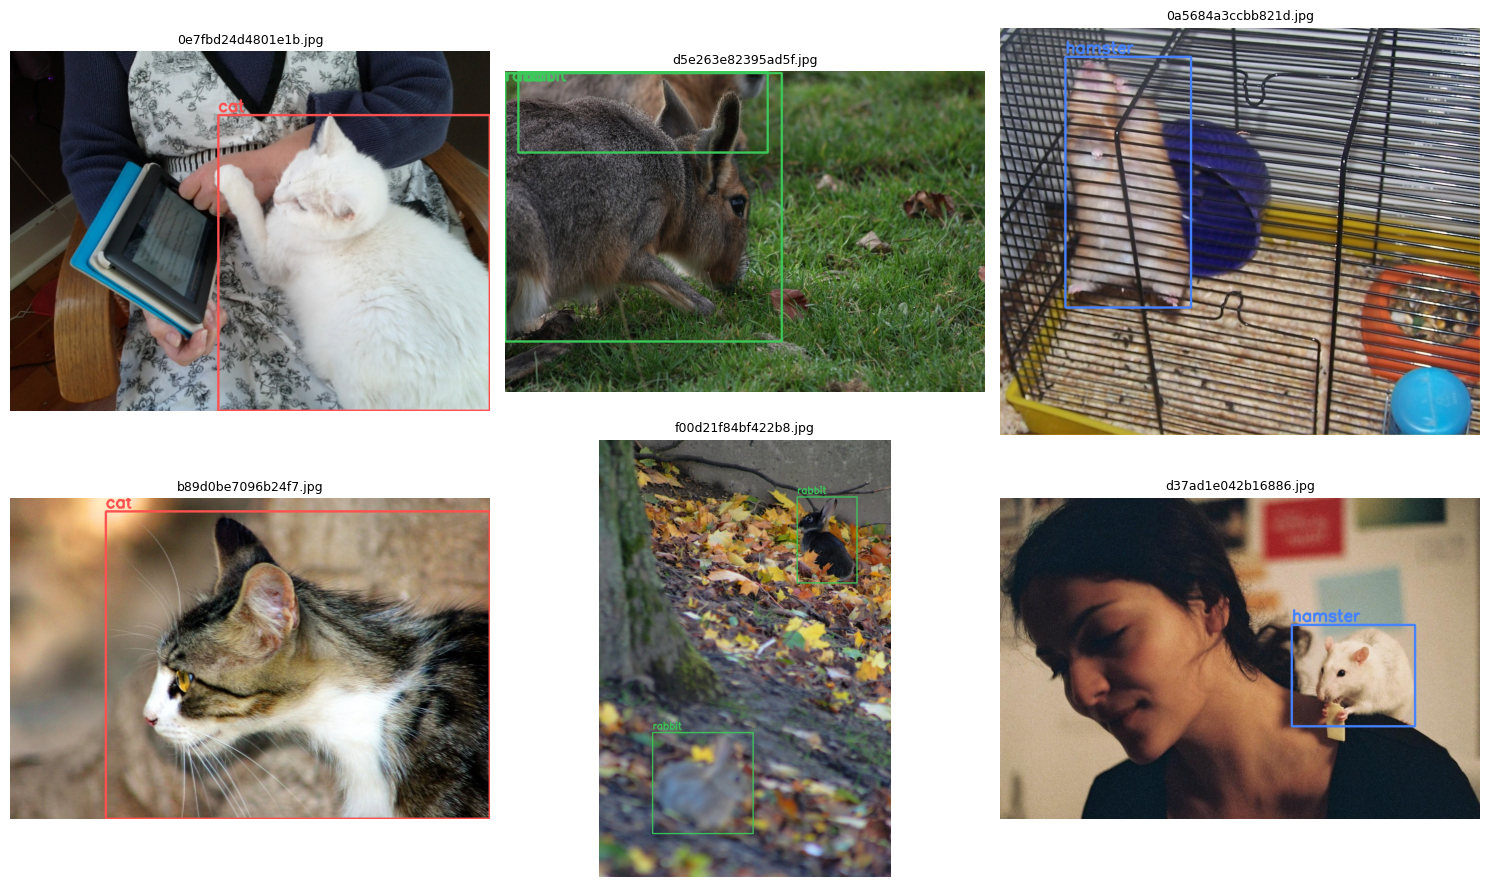

In [ ]:
COLORS = [(255, 80, 80), (60, 200, 90), (70, 130, 255)]   # 부류별 상자 색 (RGB): 빨강, 초록, 파랑


def draw_labels(img_path, labels):
    """이미지에 정답 상자와 부류 이름을 그려서 돌려준다."""
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)   # 이미지 읽고 BGR → RGB
    h, w = img.shape[:2]                                  # 이미지 높이와 너비
    thick = max(2, w // 300)                              # 이미지 크기에 맞춘 선 굵기
    font_scale = max(0.5, w / 900)                        # 이미지 크기에 맞춘 글자 크기
    for c, cx, cy, bw, bh in labels:                      # 상자 하나씩
        x1, y1 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)   # 왼쪽 위 꼭짓점 (픽셀)
        x2, y2 = int((cx + bw / 2) * w), int((cy + bh / 2) * h)   # 오른쪽 아래 꼭짓점 (픽셀)
        cv2.rectangle(img, (x1, y1), (x2, y2), COLORS[c], thick)  # 상자 그리기
        cv2.putText(img, TARGET_CLASSES[c], (x1, max(y1 - 8, 20)),   # 상자 위에 부류 이름
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale, COLORS[c], thick)
    return img


train_items = [it for it in items if it[0] == "train"]    # 학습용 이미지들
sample_items = []                                         # 그림에 넣을 이미지 (부류마다 2장)
for c in range(3):                                        # 부류마다
    only_class = [it for it in train_items if {row[0] for row in it[2]} == {c}]   # 그 부류만 있는 학습 이미지
    sample_items += only_class[:2]                        # 앞의 2장 선택
fig, axes = plt.subplots(2, 3, figsize=(15, 9))           # 2행 3열 그림판
for ax in axes.ravel():                                   # 모든 칸의
    ax.axis("off")                                        # 축 눈금 숨김
for ax, (_, img_path, labels) in zip(axes.T.ravel(), sample_items):   # 한 열이 한 부류가 되도록 배치
    ax.imshow(draw_labels(img_path, labels))              # 정답 상자를 그려 표시
    ax.set_title(img_path.name, fontsize=9)               # 파일 이름(Open Images의 이미지 ID)을 제목으로
plt.tight_layout()                                        # 여백 정리
plt.savefig(RUNS_DIR / "dataset_samples.png", dpi=120)    # 보고서·README용으로 저장
plt.show()

## 4. fine-tuning 전: 사전학습 모델은 무엇을 알고 있나

COCO 80개 부류로 사전학습된 YOLOv8은 **cat은 알고 있지만 rabbit과 hamster는 모릅니다.**
그래서 학습 전 모델은 토끼와 햄스터를 못 잡거나, 자기가 아는 부류 중 비슷한 것(cat, dog, bear 등)으로 부릅니다.

이 단계에서는 두 가지를 봅니다.

1. 부류마다 한 장씩 골라 학습 전 모델의 예측을 그림으로 확인합니다 (8단계에서 학습 후와 비교).
2. 시험용 이미지 전체에서, 실제 고양이·토끼·햄스터를 학습 전 모델이 무엇이라고 불렀는지 표로 셉니다.
   정답 상자와 IoU가 0.5 이상 겹치는 예측이 있으면 그 예측의 부류를, 없으면 "감지 없음"으로 셉니다.

`MODEL`은 사전학습 가중치입니다. `yolov8n.pt`는 가장 빠르고, `yolov8s.pt`는 더 정확하지만 학습이 조금 더 걸립니다.

bef3313ea7db9127.jpg → ['cat']
17e2b8f5c4ea60b7.jpg → ['dog', 'bed', 'person']
58b3d632b8b7de27.jpg → ['dog', 'dog']


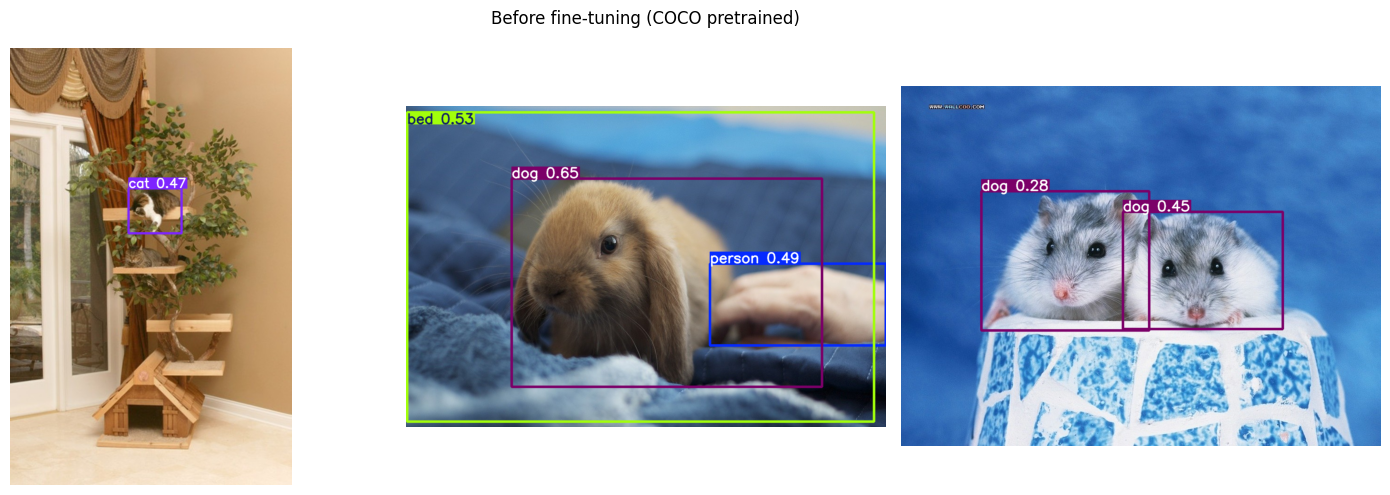

In [ ]:
MODEL = "yolov8s.pt"       # 사전학습 가중치: "yolov8n.pt"(빠름) 또는 "yolov8s.pt"(더 정확)
IMGSZ = 640                # 학습·추론 때 이미지 크기 (긴 변 기준, 픽셀)

test_items = [it for it in items if it[0] == "test"]      # 시험용 이미지들
demo_imgs = []                                            # 비교에 쓸 이미지 3장 (부류마다 한 장)
for c in range(3):                                        # 부류마다
    for _, img_path, labels in test_items:                # 시험용 이미지를 차례로 보면서
        if any(row[0] == c for row in labels) and img_path not in demo_imgs:   # 그 부류가 있고 아직 안 고른 이미지면
            demo_imgs.append(img_path)                    # 선택
            break                                         # 다음 부류로

coco_model = YOLO(MODEL)                                  # COCO로 사전학습된 모델 불러오기
before_imgs = []                                          # 학습 전 예측 그림들
for img_path in demo_imgs:                                # 이미지마다
    result = coco_model.predict(str(img_path), conf=0.25, imgsz=IMGSZ, verbose=False)[0]   # 예측 실행
    before_imgs.append(result.plot()[..., ::-1])          # 예측을 그린 그림 (BGR → RGB)
    found = [coco_model.names[int(c)] for c in result.boxes.cls]                           # 감지된 부류 이름들
    print(img_path.name, "→", found if found else "감지 없음")

fig, axes = plt.subplots(1, len(before_imgs), figsize=(15, 5))   # 가로로 나란히
for ax, img in zip(np.atleast_1d(axes), before_imgs):     # 칸마다 그림 하나
    ax.imshow(img)                                        # 표시
    ax.axis("off")                                        # 축 숨김
plt.suptitle("Before fine-tuning (COCO pretrained)")      # 그림 제목
plt.tight_layout()
plt.show()

In [ ]:
NO_DET = "감지 없음"                                       # 겹치는 예측이 없을 때의 표기
pre_rows = []                                             # (실제 부류, 학습 전 모델의 판정) 목록
for _, img_path, labels in test_items:                    # 시험용 이미지마다
    result = coco_model.predict(str(img_path), conf=0.25, imgsz=IMGSZ, verbose=False)[0]   # 학습 전 모델로 예측
    img_h, img_w = result.orig_shape                      # 원본 이미지의 높이와 너비
    preds = list(zip(result.boxes.xyxy.tolist(), result.boxes.cls.tolist()))               # (예측 상자, 부류 번호) 목록
    for c, cx, cy, bw, bh in labels:                      # 정답 상자마다
        truth = [(cx - bw / 2) * img_w, (cy - bh / 2) * img_h, (cx + bw / 2) * img_w, (cy + bh / 2) * img_h]   # 픽셀 좌표
        best_name, best_iou = NO_DET, 0.5                 # IoU 0.5 이상인 예측만 인정
        for pred_box, pred_cls in preds:                  # 예측 상자마다
            iou = iou_xyxy(truth, pred_box)               # 정답과 겹치는 정도
            if iou >= best_iou:                           # 지금까지 중 가장 많이 겹치면
                best_name, best_iou = coco_model.names[int(pred_cls)], iou   # 그 예측의 부류를 기록
        pre_rows.append({"actual": TARGET_CLASSES[c], "pretrained": best_name})

pre_df = pd.DataFrame(pre_rows, columns=["actual", "pretrained"])        # 표로 변환
top_names = [n for n in pre_df["pretrained"].value_counts().index if n != NO_DET][:5]   # 자주 나온 판정 5개
pre_df["pretrained"] = pre_df["pretrained"].where(pre_df["pretrained"].isin(top_names + [NO_DET]), "기타")   # 나머지는 '기타'
pre_table = pd.crosstab(pre_df["actual"], pre_df["pretrained"], normalize="index") * 100   # 실제 부류별 판정 비율(%)
col_order = [n for n in top_names + ["기타", NO_DET] if n in pre_table.columns]            # 열 순서: 자주 나온 순, 기타, 감지 없음
pre_table = pre_table.reindex(index=TARGET_CLASSES, columns=col_order).fillna(0).round(1)  # 행은 부류 순서로
pre_table.index.name, pre_table.columns.name = "actual", None   # 행 이름표는 actual, 열 이름표는 없음
pre_table.to_csv(RUNS_DIR / "pretrained_on_test.csv")     # 보고서·README용으로 저장
print("학습 전(COCO 사전학습) 모델이 시험용 이미지의 정답 상자를 무엇으로 판정했는지 (%, 행의 합 = 100)")
display(pre_table)

학습 전(COCO 사전학습) 모델이 시험용 이미지의 정답 상자를 무엇으로 판정했는지 (%, 행의 합 = 100)


,cat,dog,bird,bed,bear,기타,감지 없음
actual,,,,,,,
cat,75.9,1.7,1.7,1.7,0.0,0.0,19.0
rabbit,31.9,21.3,6.4,2.1,6.4,14.9,17.0
hamster,58.8,7.8,7.8,2.0,0.0,2.0,21.6


## 5. 학습 ①: 전체 fine-tuning

사전학습 가중치에서 출발해 모든 층을 3개 부류 데이터로 다시 학습합니다.
데이터의 부류 수가 3개이므로 검출 헤드의 출력이 80개에서 3개로 자동 변경됩니다
(강의자료 48쪽 "응용분야의 출력 클래스 개수에 맞게 모델 구조 변경").

학습이 끝난 실험은 다시 실행해도 건너뜁니다. 설정을 바꿔 다시 학습하려면 `FORCE_RETRAIN = True`로 바꾸세요.

In [ ]:
EPOCHS = 60                # 전체 데이터를 반복 학습하는 횟수
BATCH = 16                 # 한 번에 처리하는 이미지 수
SEED = 0                   # 결과 재현을 위한 난수 시드
PATIENCE = 20              # 검증 성능이 이만큼의 epoch 동안 안 오르면 조기 종료
FORCE_RETRAIN = False      # True: 이미 끝난 실험도 처음부터 다시 학습


def train_run(name, **extra):
    """실험 하나를 학습하고 가장 좋은 가중치(best.pt)의 경로를 돌려준다."""
    best = RUNS_DIR / name / "weights" / "best.pt"        # 이 실험의 최고 성능 가중치 위치
    if best.exists() and not FORCE_RETRAIN:               # 이미 학습이 끝났으면
        print(f"'{name}' 실험은 이미 학습되어 건너뜁니다:", best)
        return best                                       # 기존 결과 사용
    if torch.cuda.is_available():                         # GPU를 쓰는 경우
        torch.cuda.empty_cache()                          # 이전 실험이 잡아 둔 메모리를 비우고
        torch.cuda.reset_peak_memory_stats()              # 최대 사용량 기록을 초기화
    model = YOLO(MODEL)                                   # 사전학습 가중치에서 출발
    model.train(
        data=str(DATA_YAML),                              # 2단계에서 만든 3개 부류 데이터
        epochs=EPOCHS,                                    # 반복 횟수
        imgsz=IMGSZ,                                      # 이미지 크기
        batch=BATCH,                                      # 배치 크기
        seed=SEED,                                        # 난수 시드
        patience=PATIENCE,                                # 조기 종료 기준
        project=str(RUNS_DIR),                            # 결과를 저장할 상위 폴더
        name=name,                                        # 실험 이름 (하위 폴더 이름)
        exist_ok=True,                                    # 같은 이름의 폴더가 있으면 덮어씀
        **extra,                                          # 실험마다 다른 추가 설정 (예: freeze)
    )
    gpu_gb = round(torch.cuda.max_memory_reserved() / 2**30, 2) if torch.cuda.is_available() else None   # 학습 중 GPU 메모리 최대 사용량
    (RUNS_DIR / name / "train_info.json").write_text(json.dumps({"gpu_mem_gb": gpu_gb}))                 # 8단계의 요약 표에 쓰려고 저장
    return best


best_full = train_run("full")                             # 실험 ①: 모든 층을 학습

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pets3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=full, nbs=64, nms=None, opset=None, optimize=False, optimizer=aut

## 6. 학습 ②: 백본을 동결한 전이학습

강의자료 48쪽의 전이학습 설명과 같은 방식입니다.

1. 학습된 모델의 특징 추출 부분 사용 → `freeze=10`으로 백본(0~9번 층)의 가중치를 고정
2. 출력 클래스 개수에 맞게 모델 구조 변경 → 검출 헤드 출력이 3개로 변경
3. 변경된 후반부 구조만 학습 → 넥과 헤드만 학습

실험 ①과 성능, 학습 시간, GPU 메모리를 비교해 보고서의 "학습 과정 및 성능"에 넣습니다.

In [ ]:
FREEZE = 10                # 앞에서부터 고정할 층의 수 (YOLOv8의 백본은 0~9번 층)

best_freeze = train_run("freeze", freeze=FREEZE)          # 실험 ②: 백본은 고정하고 넥과 헤드만 학습

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pets3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=freeze, nbs=64, nms=None, opset=None, optimize=False, optimizer=aut

## 7. 성능 평가와 비교

학습에 쓰지 않은 **test 분할**로 두 실험을 평가합니다. 지표는 강의자료 6절의 내용과 같습니다.

- **P (Precision)**: 모델이 감지했다고 한 것 중 실제로 맞은 비율
- **R (Recall)**: 실제 객체 중 모델이 찾아낸 비율
- **mAP50**: IoU 0.5를 기준으로 맞고 틀림을 판정했을 때의 AP를 부류에 대해 평균한 값
- **mAP50-95**: IoU 기준을 0.5부터 0.95까지 바꿔가며 구한 AP의 평균 (위치가 정확해야 높게 나옴)

In [ ]:
EXPERIMENTS = {"full": best_full, "freeze": best_freeze}  # 실험 이름과 가중치 경로


def evaluate(name, weights):
    """test 분할에서 성능을 재고, 전체와 부류별 지표를 행 목록으로 돌려준다."""
    metrics = YOLO(str(weights)).val(
        data=str(DATA_YAML),                              # 3개 부류 데이터
        split="test",                                     # 시험용 분할로 평가
        imgsz=IMGSZ,                                      # 학습 때와 같은 이미지 크기
        project=str(RUNS_DIR),                            # 평가 결과 저장 위치
        name=f"{name}_test",                              # 평가 결과 폴더 이름
        exist_ok=True,                                    # 다시 실행하면 덮어씀
        verbose=False,                                    # 자세한 출력 생략
    )
    rows = [{"experiment": name, "class": "all",          # 첫 행: 전체 부류 평균
             "P": metrics.box.mp, "R": metrics.box.mr,
             "mAP50": metrics.box.map50, "mAP50-95": metrics.box.map}]
    for i, cls_id in enumerate(metrics.box.ap_class_index):   # 부류별 행
        p, r, ap50, ap = metrics.box.class_result(i)      # 그 부류의 P, R, AP50, AP50-95
        rows.append({"experiment": name, "class": metrics.names[int(cls_id)],
                     "P": p, "R": r, "mAP50": ap50, "mAP50-95": ap})
    return rows


metric_rows = []                                          # 모든 실험의 지표
for exp_name, weights in EXPERIMENTS.items():             # 실험마다
    metric_rows += evaluate(exp_name, weights)            # 평가해서 행 추가
metrics_df = pd.DataFrame(metric_rows)                    # 표로 변환
for col in ["P", "R", "mAP50", "mAP50-95"]:               # 숫자 열을
    metrics_df[col] = metrics_df[col].astype(float).round(4)   # 소수 넷째 자리까지
metrics_df.to_csv(RUNS_DIR / "metrics_test.csv", index=False)  # 보고서·README용으로 저장
display(metrics_df)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 28.6±24.1 MB/s, size: 155.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/pets3/test/labels... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 382.9it/s 0.3s
val: New cache created: /content/pets3/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.1it/s 2.6s
                   all        120        156      0.803      0.726      0.752      0.479
Speed: 2.4ms preprocess, 8.0ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs_pets/full_test
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 1

,experiment,class,P,R,mAP50,mAP50-95
0,full,all,0.8033,0.7261,0.7522,0.4787
1,full,cat,0.7018,0.6207,0.6335,0.3233
2,full,rabbit,0.8667,0.8298,0.8596,0.6847
3,full,hamster,0.8414,0.7280,0.7636,0.4279
4,freeze,all,0.7187,0.6998,0.7288,0.4591
5,freeze,cat,0.7656,0.6194,0.6738,0.3843
6,freeze,rabbit,0.6032,0.8723,0.8180,0.6333
7,freeze,hamster,0.7873,0.6078,0.6945,0.3595


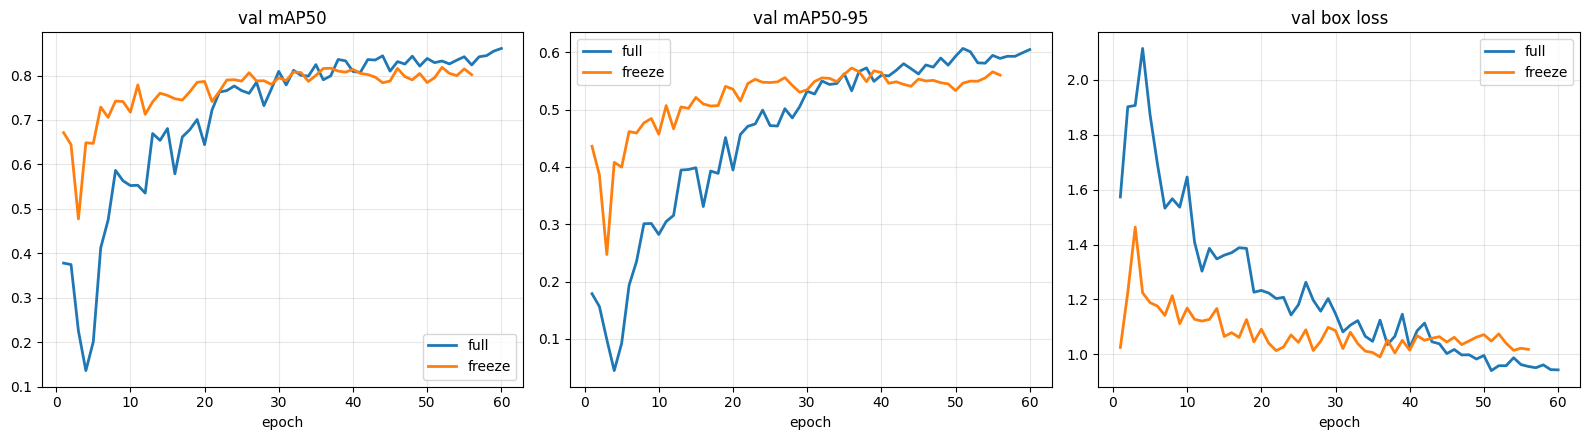

,experiment,epochs_run,best_epoch,val_mAP50,val_mAP50-95,train_minutes,gpu_mem_gb
0,full,60,51,0.8289,0.6068,16.5,4.91
1,freeze,56,36,0.8157,0.5727,14.4,3.18


최종 선택 모델: full → /content/runs_pets/full/weights/best.pt 


In [ ]:
def load_history(name):
    """실험의 epoch별 학습 기록(results.csv)을 표로 읽는다."""
    history = pd.read_csv(RUNS_DIR / name / "results.csv")   # Ultralytics가 저장한 학습 기록
    history.columns = [c.strip() for c in history.columns]   # 열 이름의 앞뒤 공백 제거
    return history


histories = {name: load_history(name) for name in EXPERIMENTS}   # 실험별 학습 기록
curve_cols = [("metrics/mAP50(B)", "val mAP50"),          # (기록의 열 이름, 그래프 제목)
              ("metrics/mAP50-95(B)", "val mAP50-95"),
              ("val/box_loss", "val box loss")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))         # 그래프 3개를 가로로
for ax, (col, title) in zip(axes, curve_cols):            # 그래프마다
    for name, history in histories.items():               # 실험마다 선 하나
        ax.plot(history["epoch"], history[col], label=name, linewidth=2)   # epoch에 따른 변화
    ax.set_title(title)                                   # 그래프 제목
    ax.set_xlabel("epoch")                                # 가로축 이름
    ax.grid(alpha=0.3)                                    # 옅은 격자
    ax.legend()                                           # 범례
plt.tight_layout()
plt.savefig(RUNS_DIR / "compare_curves.png", dpi=120)     # 보고서·README용으로 저장
plt.show()

summary_rows = []                                         # 실험별 요약
for name, history in histories.items():                   # 실험마다
    best_row = history.loc[history["metrics/mAP50-95(B)"].idxmax()]   # 검증 mAP50-95가 가장 높은 epoch
    info_path = RUNS_DIR / name / "train_info.json"       # 학습 때 저장한 GPU 메모리 기록
    info = json.loads(info_path.read_text()) if info_path.exists() else {}
    summary_rows.append({
        "experiment": name,                               # 실험 이름
        "epochs_run": int(history["epoch"].max()),        # 실제로 학습한 epoch 수 (조기 종료 반영)
        "best_epoch": int(best_row["epoch"]),             # 최고 성능이 나온 epoch
        "val_mAP50": round(float(best_row["metrics/mAP50(B)"]), 4),        # 그때의 검증 mAP50
        "val_mAP50-95": round(float(best_row["metrics/mAP50-95(B)"]), 4),  # 그때의 검증 mAP50-95
        "train_minutes": round(float(history["time"].max()) / 60, 1) if "time" in history else None,   # 학습 시간(분)
        "gpu_mem_gb": info.get("gpu_mem_gb"),             # 학습 중 GPU 메모리 최대 사용량(GB)
    })
summary_df = pd.DataFrame(summary_rows)                   # 표로 변환
summary_df.to_csv(RUNS_DIR / "train_summary.csv", index=False)   # 저장
display(summary_df)

FINAL_MODEL = None         # None: 검증 mAP50-95가 더 높은 실험을 자동 선택 / "full" 또는 "freeze": 직접 지정

AUTO_NAME = summary_df.sort_values("val_mAP50-95", ascending=False).iloc[0]["experiment"]   # 검증 성능이 더 좋은 실험
BEST_NAME = FINAL_MODEL or AUTO_NAME                      # 직접 지정했으면 그 실험, 아니면 자동 선택
BEST_WEIGHTS = EXPERIMENTS[BEST_NAME]                     # 그 실험의 가중치 → 영상 제작과 제출에 사용
print("최종 선택 모델:", BEST_NAME, "→", BEST_WEIGHTS, "" if BEST_NAME == AUTO_NAME else f"(자동 선택이었다면 {AUTO_NAME})")

아래는 선택된 모델의 학습 곡선, 혼동 행렬, PR 곡선입니다. 세 그림은 학습 중 **검증(valid) 분할**로 계산된 것입니다.

- **학습 곡선**: 손실이 줄고 mAP가 오르다가 평평해지면 학습이 수렴한 것입니다.
- **혼동 행렬**: 어떤 부류를 어떤 부류로 착각했는지, 배경으로 놓친 것이 얼마나 되는지 보여줍니다.
  토끼와 햄스터처럼 생김새가 비슷한 부류가 서로 헷갈리는지 확인해 보세요.
- **PR 곡선**: 곡선 아래 면적이 AP입니다 (강의자료 45쪽).

results.png


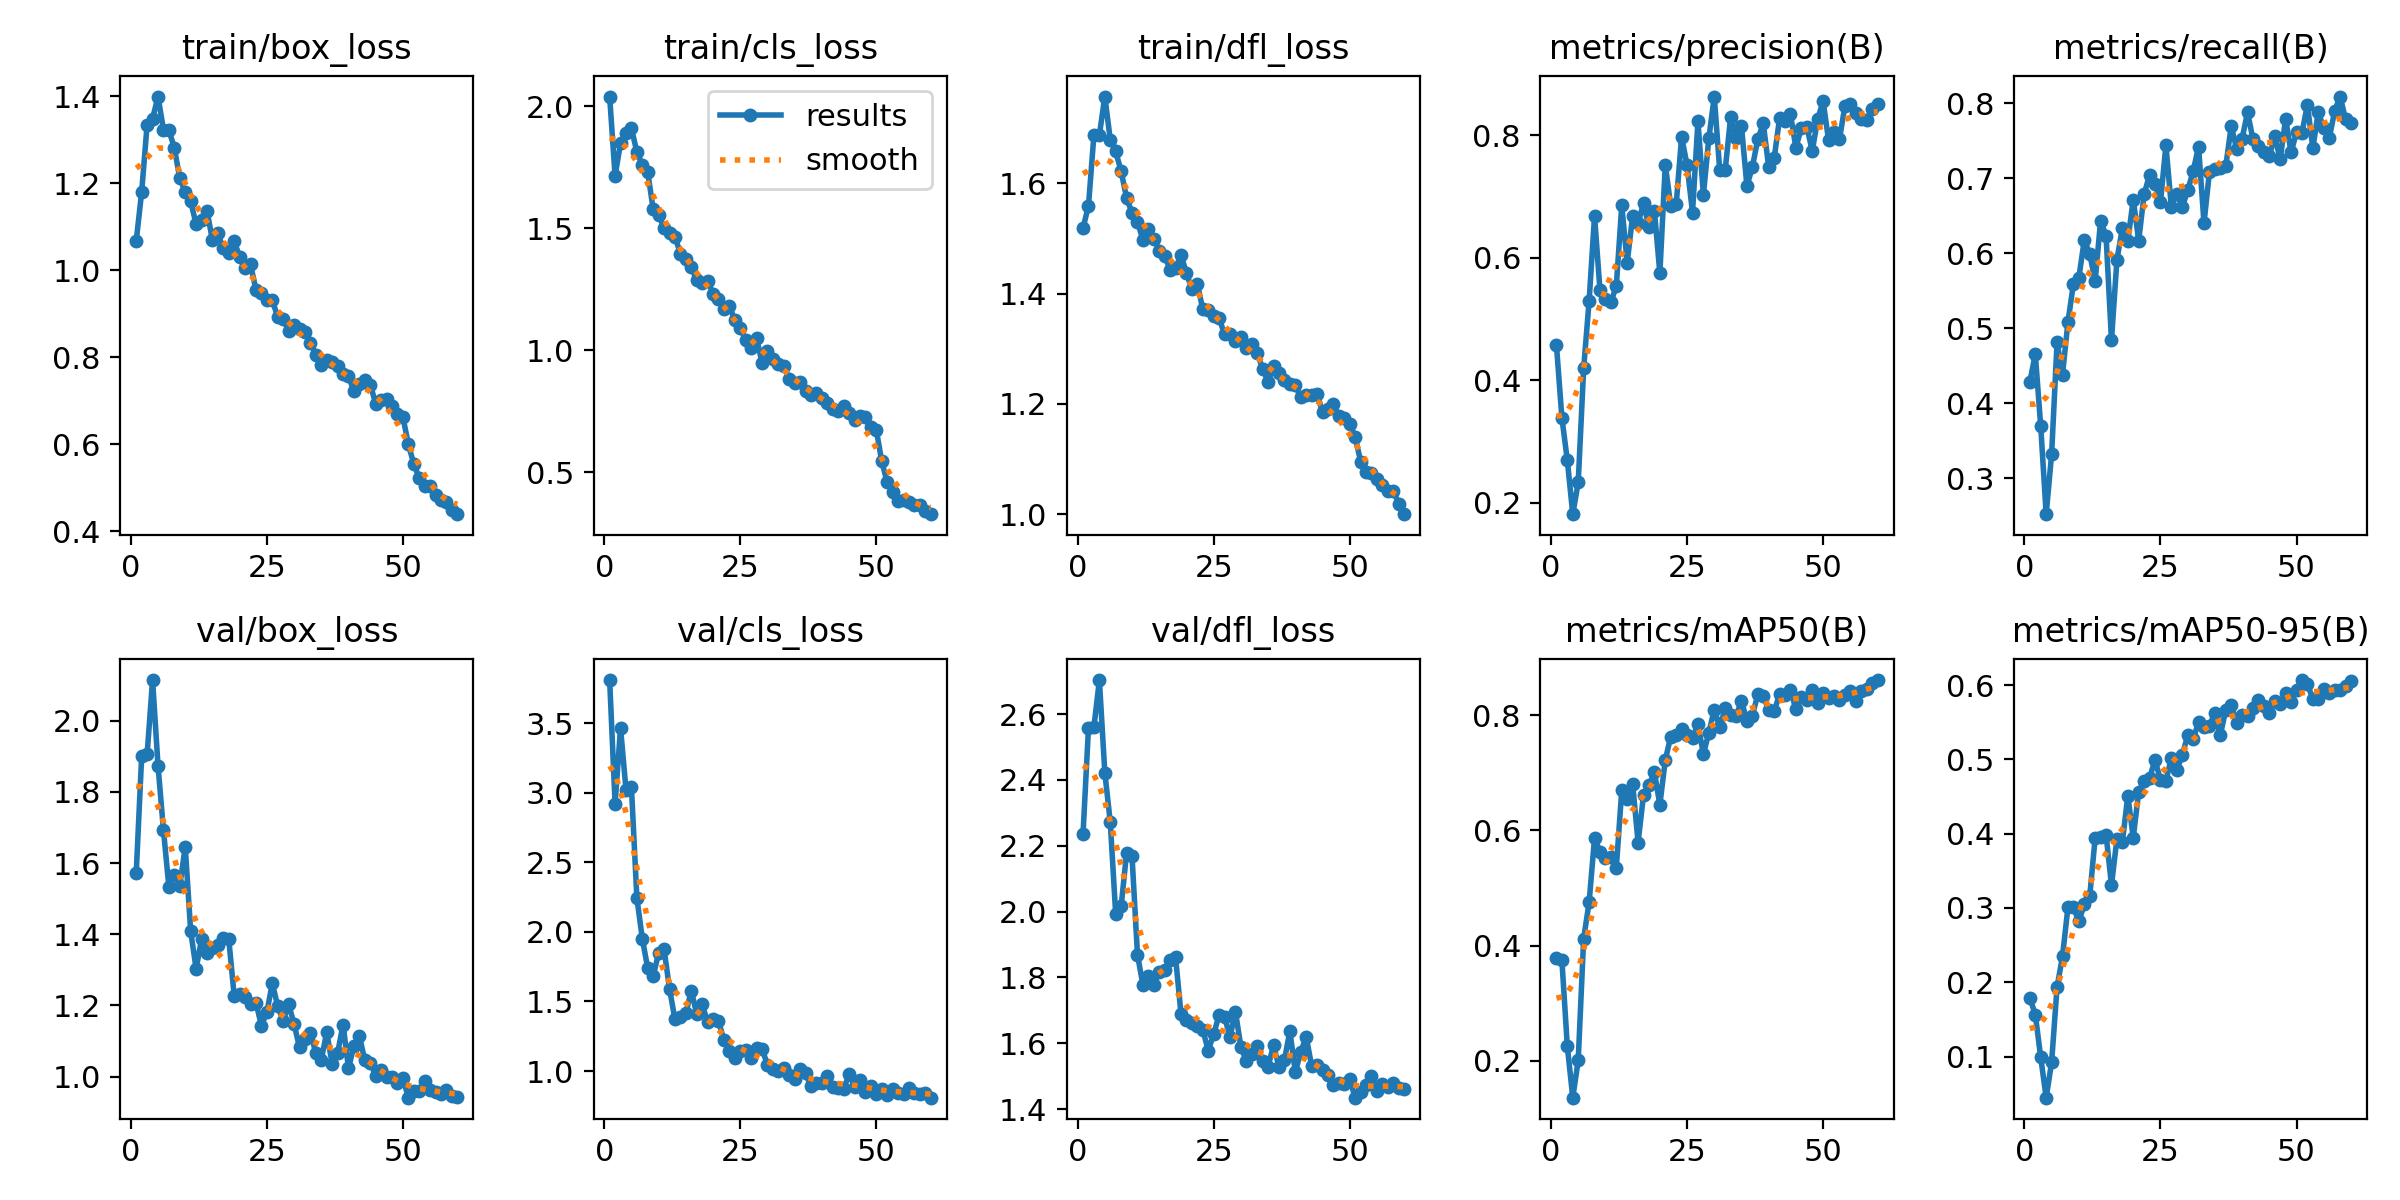

confusion_matrix_normalized.png


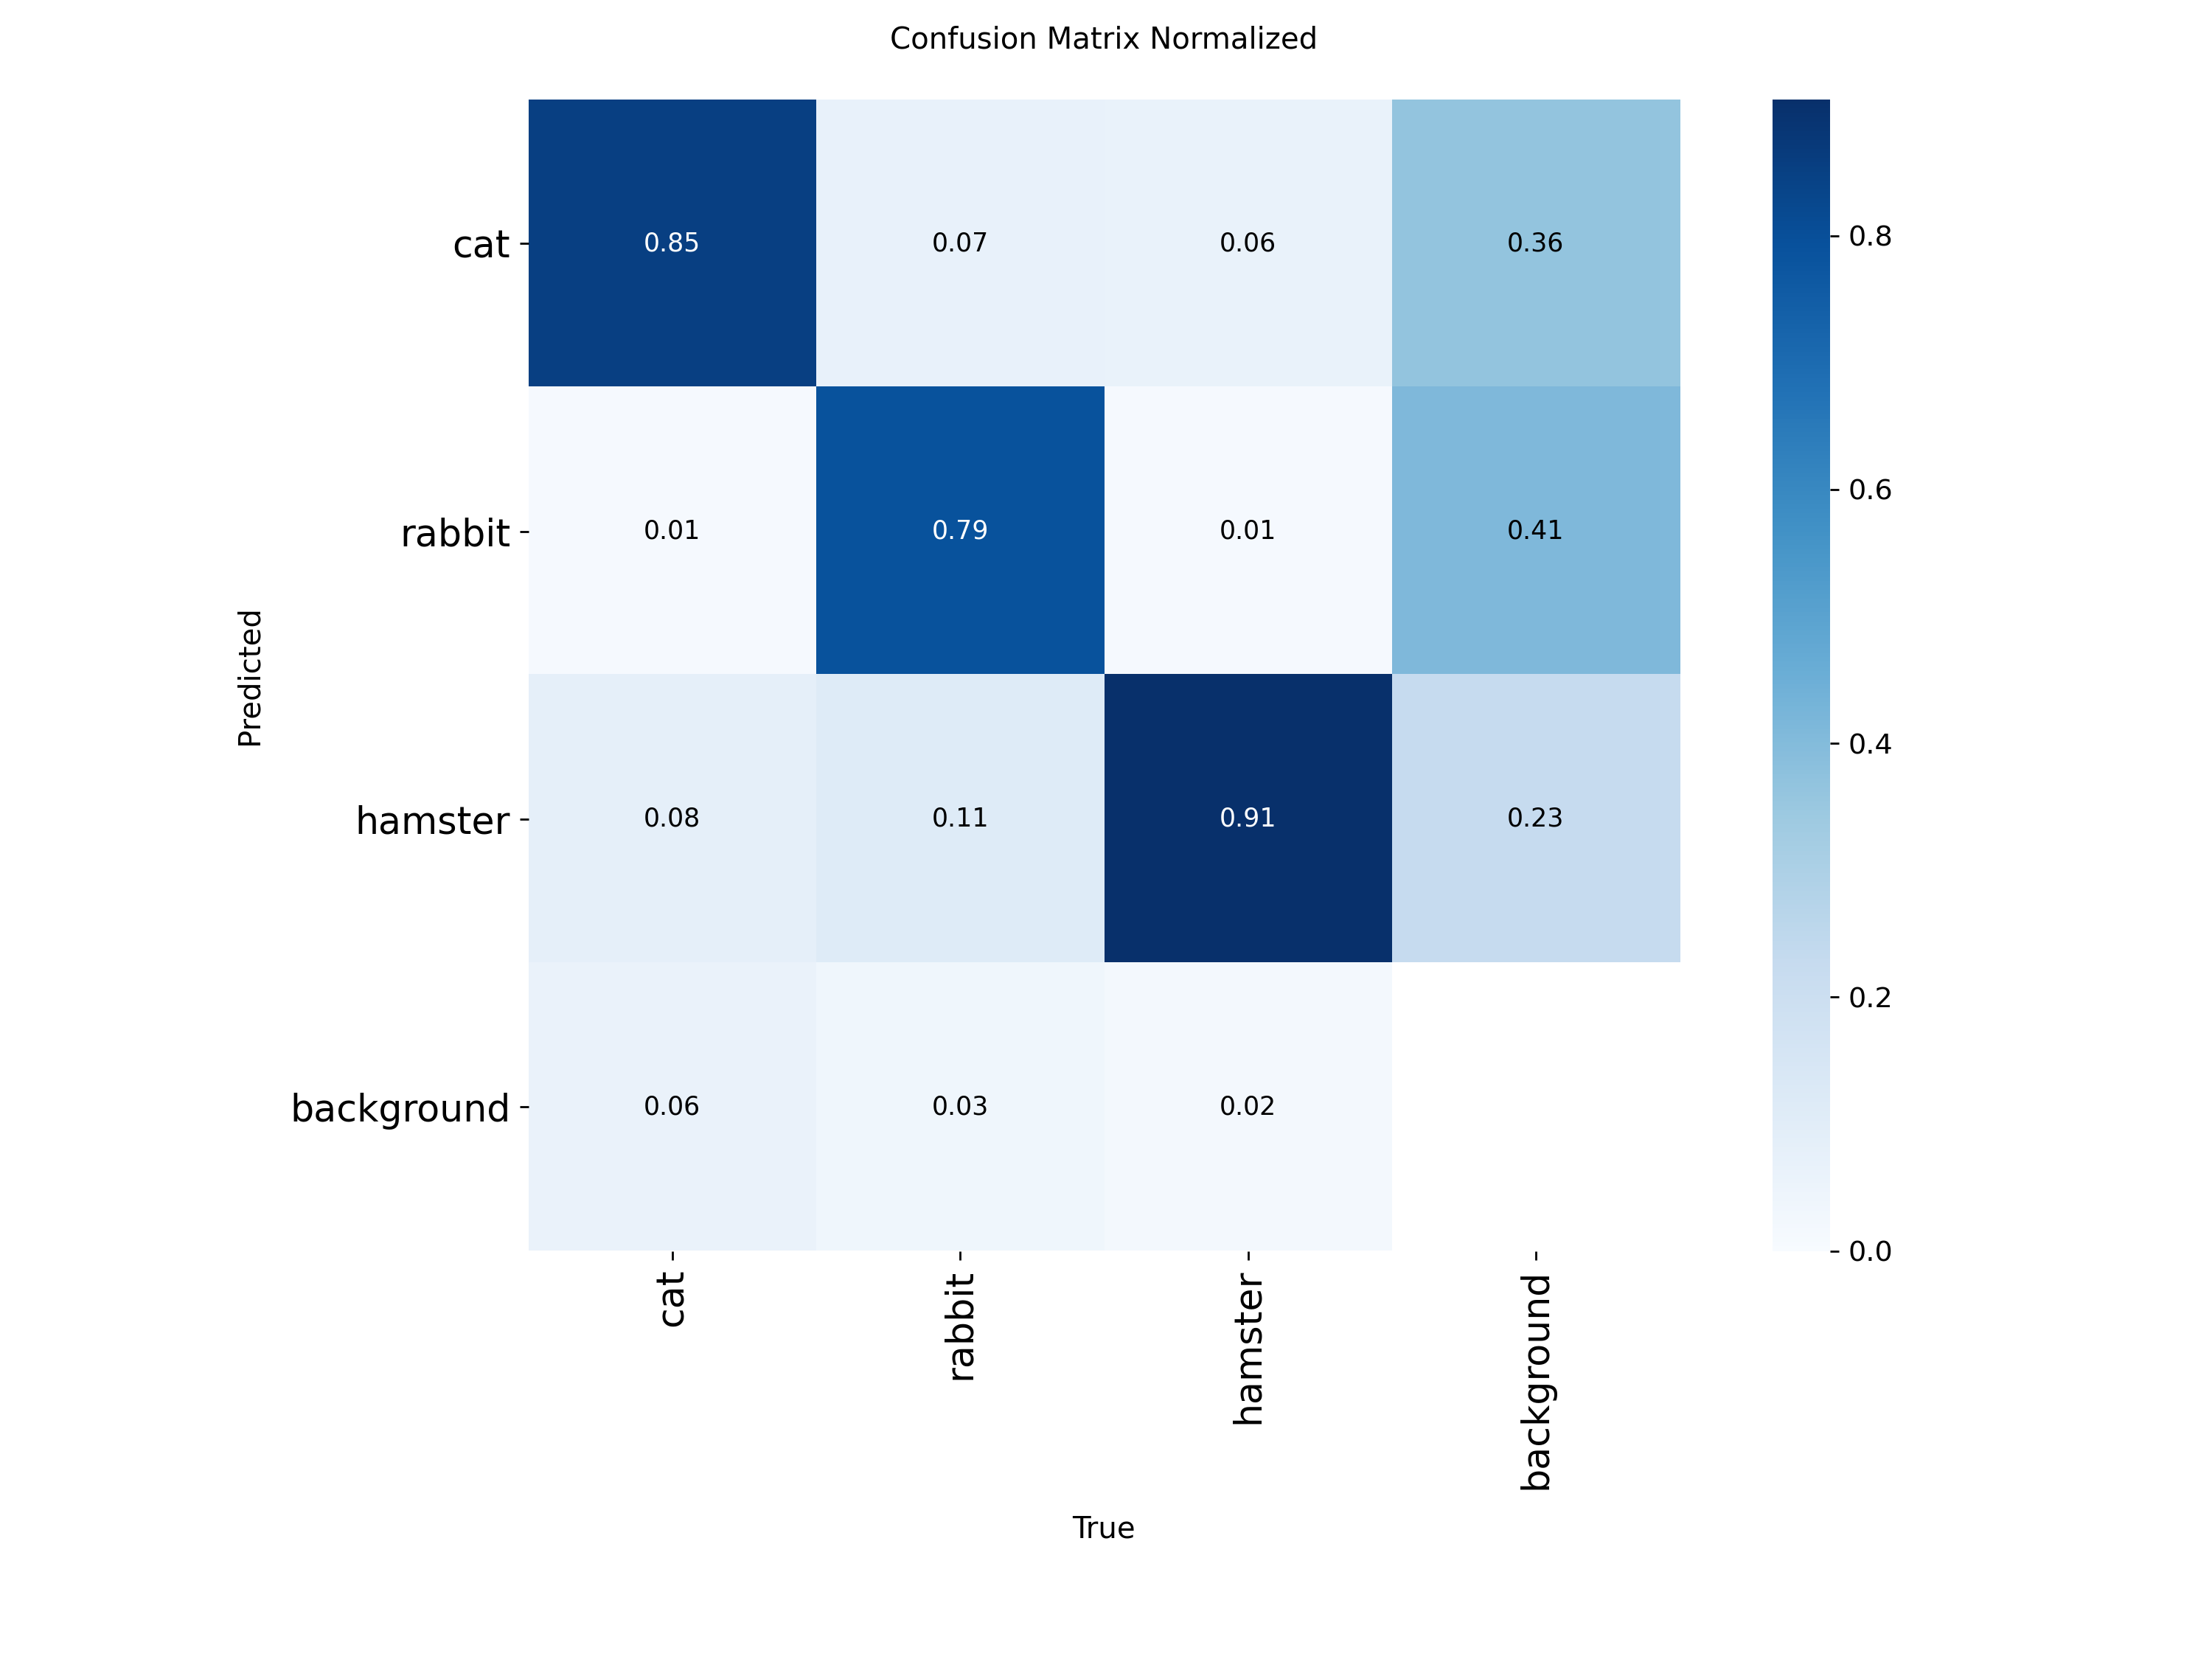

BoxPR_curve.png


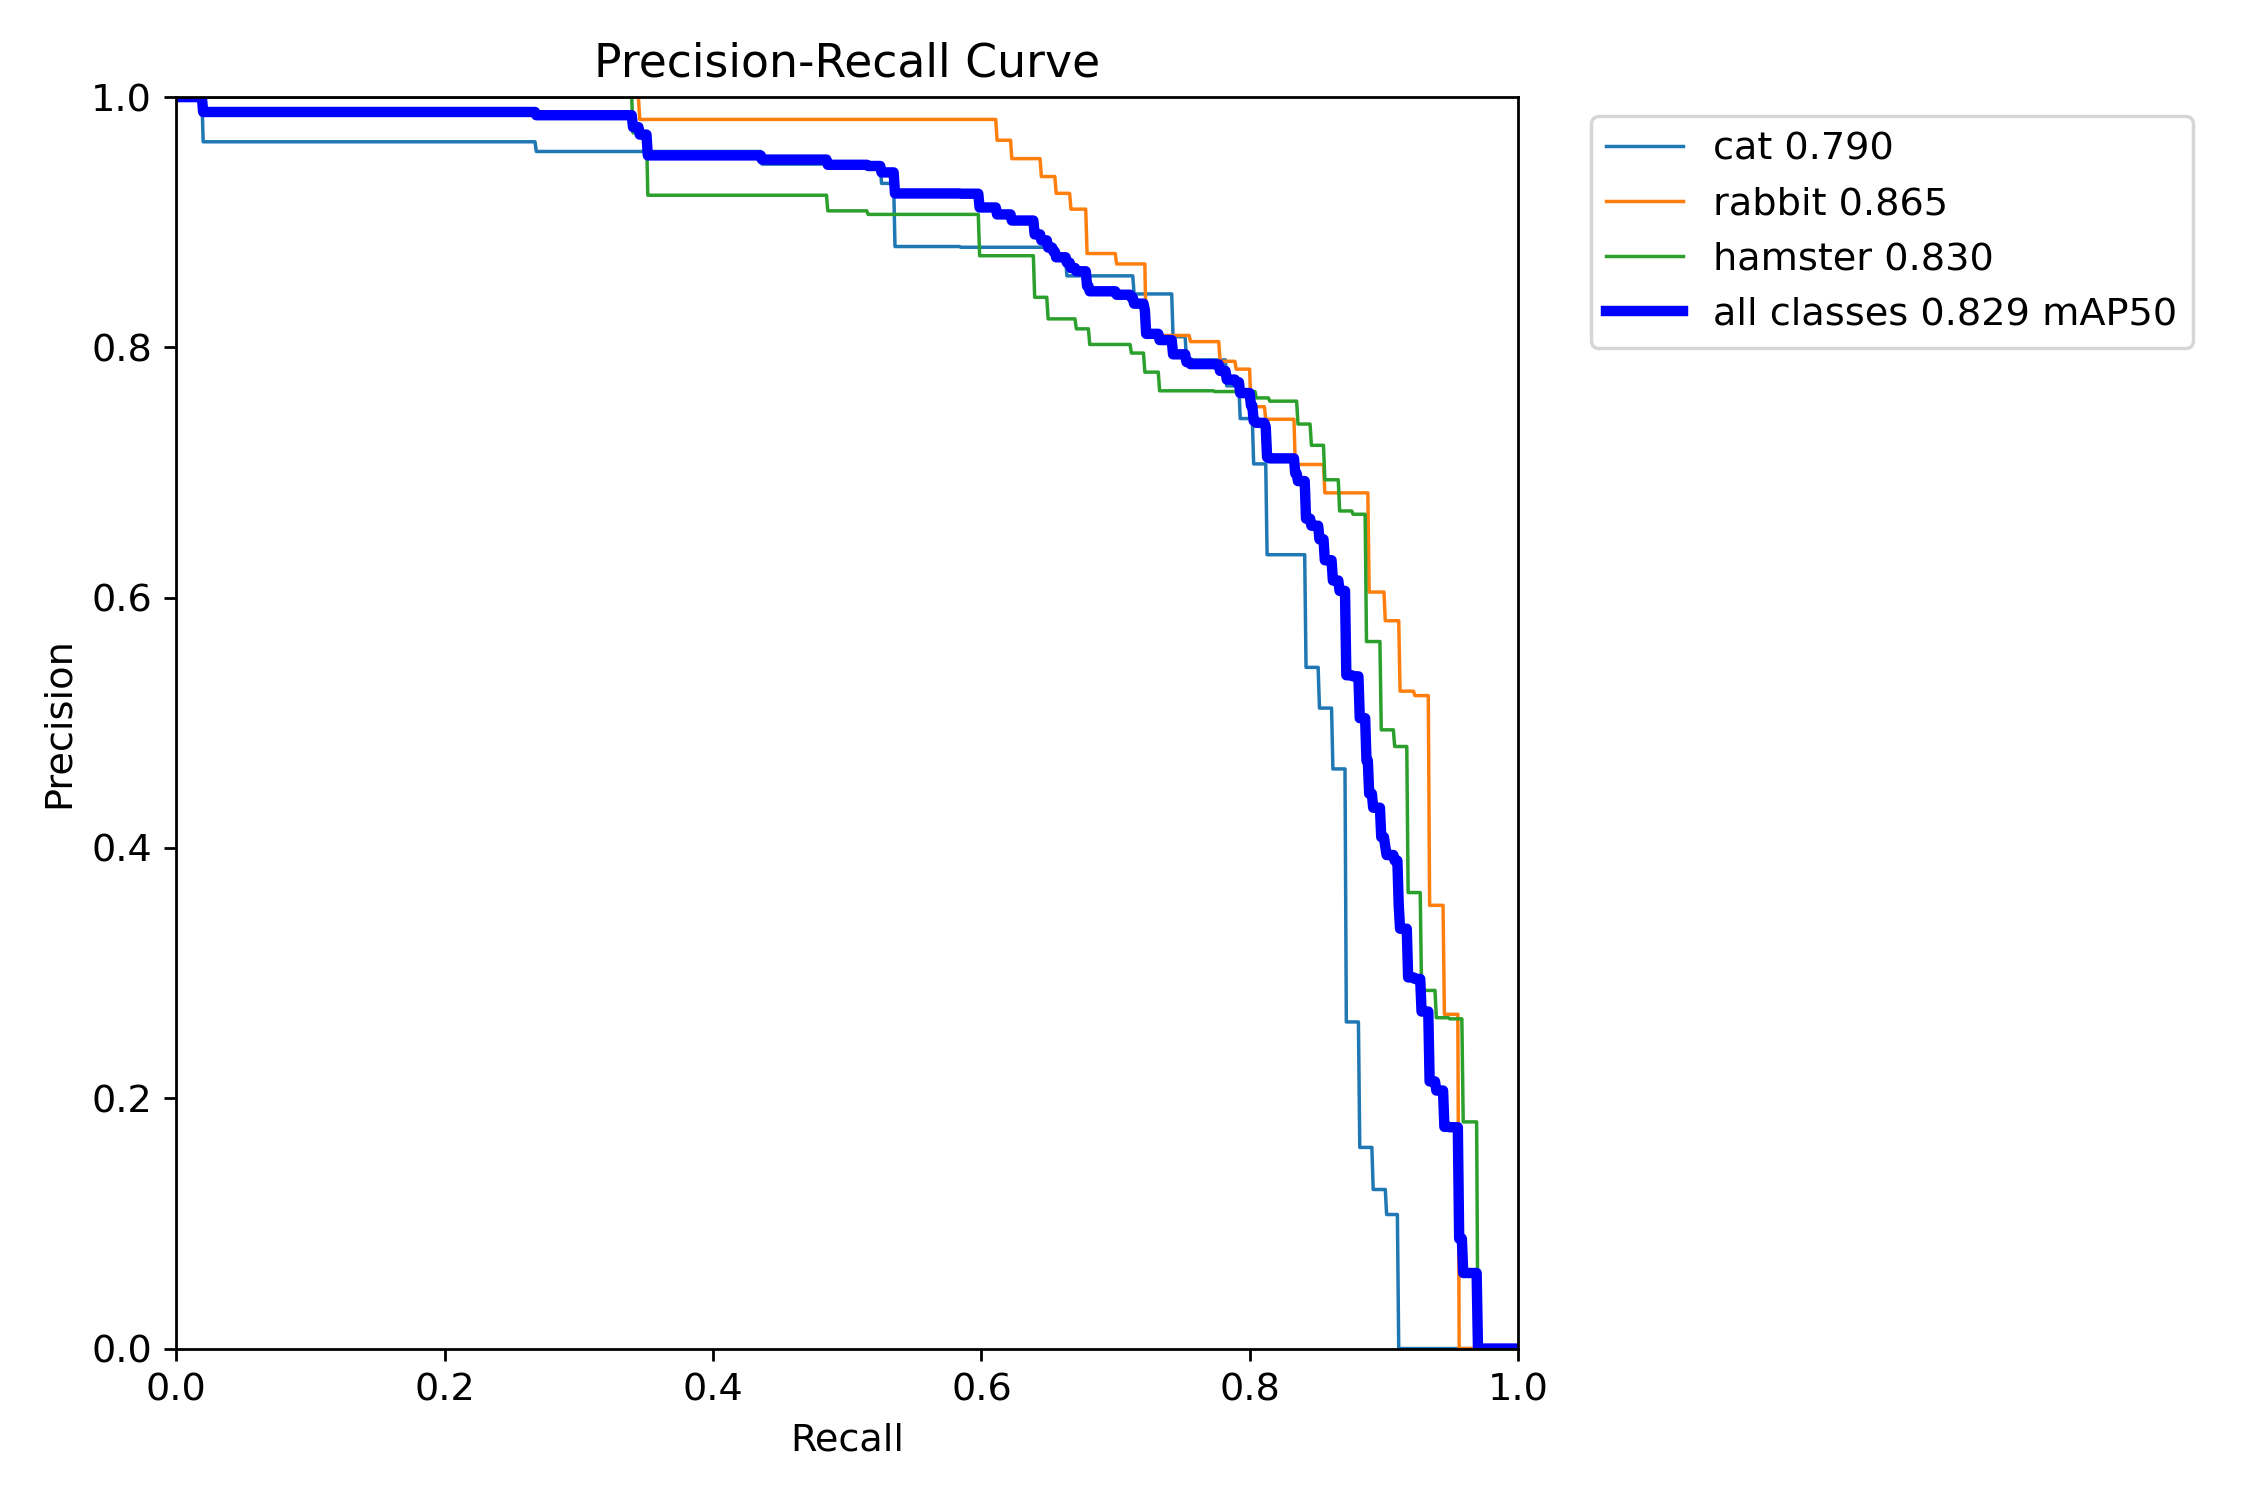

In [ ]:
best_dir = RUNS_DIR / BEST_NAME                           # 선택된 실험의 결과 폴더
plot_files = [best_dir / "results.png",                   # 학습 곡선
              best_dir / "confusion_matrix_normalized.png"]   # 정규화된 혼동 행렬
plot_files += sorted(best_dir.glob("*PR_curve.png"))      # PR 곡선 (버전에 따라 파일 이름 앞부분이 다름)
for plot_path in plot_files:                              # 그림마다
    if plot_path.exists():                                # 파일이 있으면
        print(plot_path.name)                             # 파일 이름 출력
        display(Image(filename=str(plot_path), width=900))    # 노트북에 표시

## 8. fine-tuning 후: 같은 이미지로 다시 예측

4단계와 같은 이미지에 학습된 모델을 적용해 위아래로 비교합니다. 윗줄이 학습 전, 아랫줄이 학습 후입니다.

bef3313ea7db9127.jpg → 감지 없음
17e2b8f5c4ea60b7.jpg → ['rabbit 0.79']
58b3d632b8b7de27.jpg → ['hamster 0.84', 'hamster 0.80']


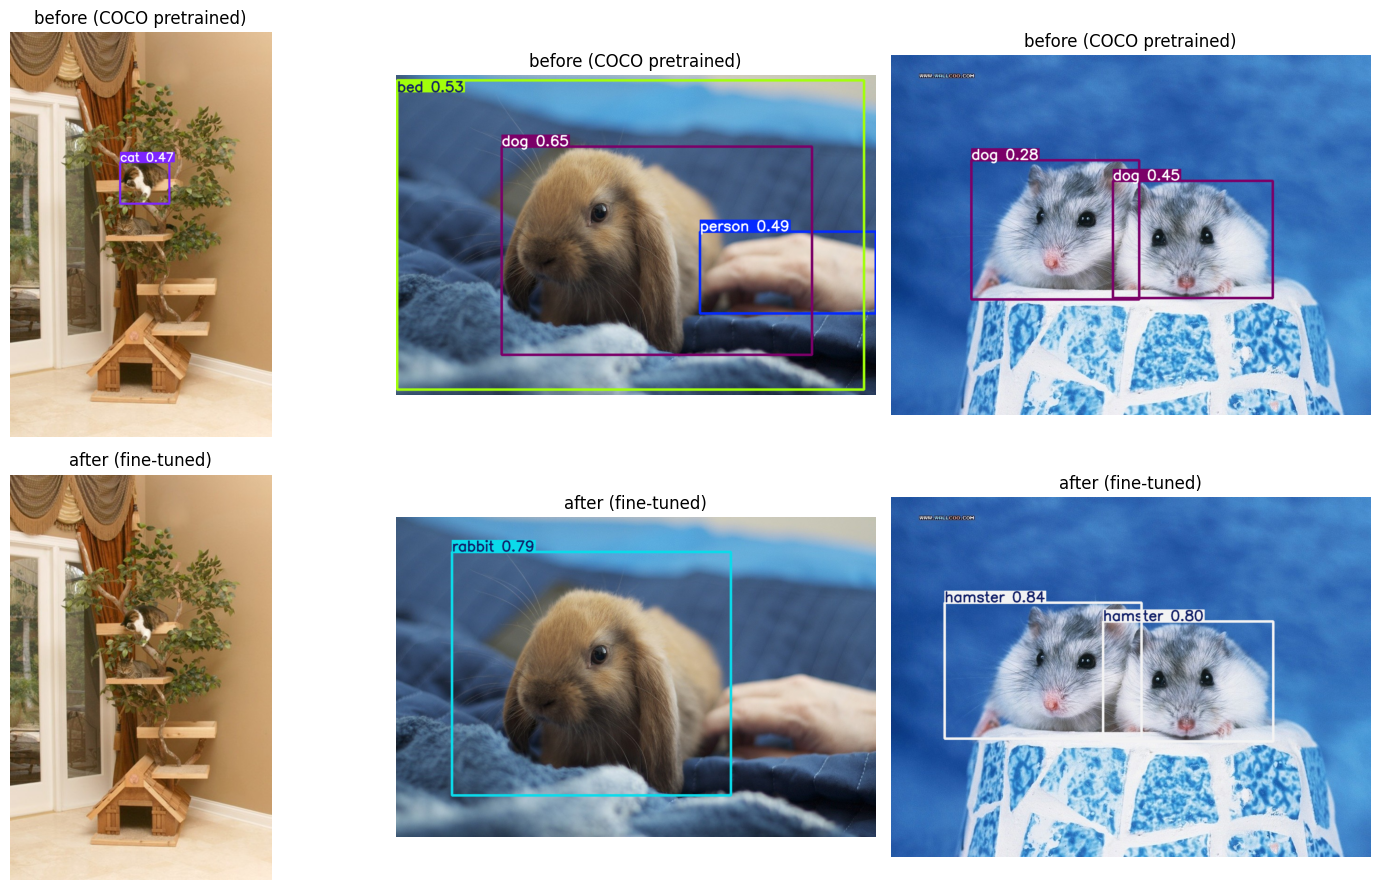

In [ ]:
best_model = YOLO(str(BEST_WEIGHTS))                      # fine-tuning된 모델 불러오기
after_imgs = []                                           # 학습 후 예측 그림들
for img_path in demo_imgs:                                # 4단계와 같은 이미지
    result = best_model.predict(str(img_path), conf=0.25, imgsz=IMGSZ, verbose=False)[0]   # 예측 실행
    after_imgs.append(result.plot()[..., ::-1])           # 예측을 그린 그림 (BGR → RGB)
    found = [f"{best_model.names[int(c)]} {p:.2f}" for c, p in zip(result.boxes.cls, result.boxes.conf)]   # 부류와 확신도
    print(img_path.name, "→", found if found else "감지 없음")

fig, axes = plt.subplots(2, len(demo_imgs), figsize=(15, 9), squeeze=False)   # 2행: 학습 전 / 학습 후
for col in range(len(demo_imgs)):                         # 이미지마다
    axes[0, col].imshow(before_imgs[col])                 # 윗줄: 학습 전
    axes[0, col].set_title("before (COCO pretrained)")    # 윗줄 제목
    axes[1, col].imshow(after_imgs[col])                  # 아랫줄: 학습 후
    axes[1, col].set_title("after (fine-tuned)")          # 아랫줄 제목
    axes[0, col].axis("off")                              # 축 숨김
    axes[1, col].axis("off")
plt.tight_layout()
plt.savefig(RUNS_DIR / "before_after.png", dpi=120)       # 보고서·README용으로 저장
plt.show()

## 9. 감지·추적 결과 5초 영상 만들기

**영상 준비**: [Pexels](https://www.pexels.com/videos/), [Pixabay](https://pixabay.com/videos/), [Mixkit](https://mixkit.co/free-stock-video/)에서
고양이, 토끼, 햄스터 영상을 하나씩 받으세요. 세 동물이 한 영상에 같이 나오기는 어려우므로 영상 3개를 이어 붙입니다.

- 동물이 화면에 크게 보이고, 한두 마리만 나오는 장면이 잘 잡힙니다. 햄스터는 몸집이 작으니 가까이서 찍은 영상을 고르세요.
- 실제 동물을 찍은 영상이어야 합니다. 만화, 인형, AI로 만든 영상은 피하세요.
- 동물이 걷거나 움직이는 장면이어야 추적 궤적이 그려집니다.
- 가로 영상, 1280×720 이상을 권합니다.

1단계에서 영상을 올렸다면 아래 셀은 목록만 보여 주고 넘어갑니다. 올린 영상이 없을 때만 업로드 창이 뜹니다.
영상을 바꾸고 싶으면 왼쪽 파일 탐색기의 `videos` 폴더에서 지우거나 끌어다 놓은 뒤 이 셀부터 다시 실행하세요.

In [ ]:
if IN_COLAB and not list_videos():                        # 아직 올린 영상이 없으면
    upload_videos()                                       # 업로드 창 열기


def video_info(path):
    """영상의 (길이 초, 너비, 높이, 초당 프레임 수)를 돌려준다."""
    cap = cv2.VideoCapture(str(path))                     # 영상 열기
    fps = cap.get(cv2.CAP_PROP_FPS) or 30                 # 초당 프레임 수 (못 읽으면 30으로 가정)
    n_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)          # 전체 프레임 수
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))        # 너비
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))      # 높이
    cap.release()                                         # 영상 닫기
    return n_frames / fps, width, height, fps


video_files = list_videos()                               # 올라온 영상 목록
assert video_files, "videos 폴더에 영상이 없습니다. 영상을 올린 뒤 이 셀을 다시 실행하세요."
for path in video_files:                                  # 영상마다 정보 출력
    seconds, width, height, fps = video_info(path)
    print(f"{path.name}: {seconds:.1f}초, {width}x{height}, {fps:.0f}fps")

141719-778319475.mp4: 8.9초, 1920x1080, 25fps
14185886_1080_1920_30fps.mp4: 13.4초, 1080x1920, 30fps
179212-861403629.mp4: 15.9초, 1920x1080, 24fps


**구간 지정**: `CLIPS`에 (파일 이름, 시작 초, 길이 초)를 적습니다. 길이의 합이 5초가 되게 하세요.

- `CLIPS = None`이면 올린 영상들을 앞에서부터 같은 길이로 잘라 합계 5초를 만듭니다.
- 예: `CLIPS = [("cat.mp4", 2.0, 1.7), ("rabbit.mp4", 0.0, 1.7), ("hamster.mp4", 4.0, 1.6)]`

구간마다 추적기를 새로 시작하므로, 추적 ID는 구간 안에서만 이어집니다.
결과를 보고 동물이 잘 안 잡히면 시작 초를 바꾸거나 `CONF`를 낮춰 다시 실행하세요.
추적 ID가 자주 바뀌면 `TRACKER`를 바꿔 비교해 보세요. 이런 시도는 보고서의 "경험한 내용"에 쓸 수 있습니다.

In [ ]:
CLIPS = None                   # None: 자동 / 직접 지정 예: [("cat.mp4", 2.0, 1.7), ("rabbit.mp4", 0.0, 1.7), ("hamster.mp4", 4.0, 1.6)]
TOTAL_SEC = 5.0                # 최종 영상 길이 (과제 조건: 5초 분량)
TRACKER = "botsort.yaml"       # 추적 알고리즘: "botsort.yaml" 또는 "bytetrack.yaml"
CONF = 0.35                    # 이 확신도보다 낮은 감지는 버림 (강의자료 44쪽의 confidence 임계값)
OUT_W, OUT_H, OUT_FPS = 1280, 720, 30   # 최종 영상의 너비, 높이, 초당 프레임 수
TRAIL = 30                     # 이동 궤적으로 그릴 최근 프레임 수

if CLIPS is None:                                         # 자동 구간: 영상마다 같은 길이
    CLIPS = [(p.name, 0.0, TOTAL_SEC / len(video_files)) for p in video_files]
total = sum(c[2] for c in CLIPS)                          # 구간 길이의 합
print("사용할 구간:", CLIPS)
if abs(total - TOTAL_SEC) > 0.1:                          # 합이 5초와 다르면 알림
    print(f"주의: 구간 길이의 합이 {total:.1f}초입니다. 과제 조건은 {TOTAL_SEC:.0f}초 분량입니다.")

if WORK_DIR.exists():                                     # 이전 작업 파일이 있으면
    shutil.rmtree(WORK_DIR)                               # 지우고
WORK_DIR.mkdir()                                          # 새로 만듦


def cut_clip(src, start, duration, dst):
    """영상의 한 구간을 잘라 해상도와 프레임 수를 통일한 mp4로 저장한다."""
    vf = (f"scale={OUT_W}:{OUT_H}:force_original_aspect_ratio=decrease,"   # 비율을 유지하며 축소·확대
          f"pad={OUT_W}:{OUT_H}:(ow-iw)/2:(oh-ih)/2,"                      # 남는 부분은 검은 여백으로 채움
          f"fps={OUT_FPS}")                                                 # 초당 프레임 수 통일
    cmd = ["ffmpeg", "-y", "-loglevel", "error",          # 덮어쓰기 허용, 오류만 출력
           "-ss", str(start), "-t", str(duration),        # 시작 위치와 길이
           "-i", str(src), "-vf", vf, "-an",              # 입력 파일, 영상 필터, 소리 제거
           "-c:v", "libx264", "-crf", "18", "-pix_fmt", "yuv420p", str(dst)]   # H.264로 저장
    subprocess.run(cmd, check=True)                       # ffmpeg 실행 (실패하면 오류 발생)


clip_files = []                                           # 잘라낸 구간 파일들
for i, (video_name, start, duration) in enumerate(CLIPS): # 구간마다
    src = VIDEO_DIR / video_name                          # 원본 영상
    assert src.exists(), f"{video_name} 파일이 videos 폴더에 없습니다."
    dst = WORK_DIR / f"clip_{i + 1}.mp4"                  # 잘라낸 파일 이름
    cut_clip(src, start, duration, dst)                   # 구간 자르기
    clip_files.append(dst)

track_rows = []                                           # 프레임별 추적 기록 (CSV로 저장)
frames_with_det = 0                                       # 객체가 하나라도 잡힌 프레임 수
frame_no = 0                                              # 전체 프레임 번호
raw_video = WORK_DIR / "tracked_raw.mp4"                  # 그림을 그려 넣은 중간 영상
writer = cv2.VideoWriter(str(raw_video), cv2.VideoWriter_fourcc(*"mp4v"), OUT_FPS, (OUT_W, OUT_H))   # 영상 저장 도구

for clip_idx, clip_path in enumerate(clip_files):         # 잘라낸 구간마다
    track_model = YOLO(str(BEST_WEIGHTS))                 # 모델을 새로 불러와 추적기를 초기화
    trails = defaultdict(lambda: deque(maxlen=TRAIL))     # 추적 ID별 최근 중심점들
    cap = cv2.VideoCapture(str(clip_path))                # 구간 영상 열기
    while True:                                           # 프레임을 하나씩 처리
        ok, frame = cap.read()                            # 프레임 읽기
        if not ok:                                        # 더 읽을 프레임이 없으면
            break                                         # 이 구간 종료
        result = track_model.track(frame, persist=True, tracker=TRACKER,   # persist=True: 이전 프레임의 추적을 이어감
                                   conf=CONF, imgsz=IMGSZ, verbose=False)[0]
        canvas = result.plot(line_width=2)                # 상자, 추적 ID, 부류, 확신도가 그려진 프레임
        boxes_now = result.boxes                          # 이 프레임의 감지 결과
        if boxes_now.id is not None:                      # 추적 ID가 붙은 객체가 있으면
            frames_with_det += 1                          # 감지된 프레임 수 +1
            for (cx, cy, w, h), tid, cls, conf in zip(boxes_now.xywh.tolist(), boxes_now.id.int().tolist(),
                                                      boxes_now.cls.int().tolist(), boxes_now.conf.tolist()):
                trails[tid].append((int(cx), int(cy)))    # 중심점을 궤적에 추가
                track_rows.append({"frame": frame_no, "clip": clip_idx + 1, "track_id": tid,   # 기록 한 줄
                                   "class": track_model.names[cls], "conf": round(conf, 3),
                                   "cx": round(cx, 1), "cy": round(cy, 1), "w": round(w, 1), "h": round(h, 1)})
                if len(trails[tid]) > 1:                  # 점이 2개 이상이면 궤적 선 그리기
                    points = np.array(trails[tid], dtype=np.int32).reshape(-1, 1, 2)   # OpenCV가 받는 점 배열 형태
                    cv2.polylines(canvas, [points], False, (255, 255, 255), 2)         # 흰색 궤적
        writer.write(canvas)                              # 결과 프레임 저장
        frame_no += 1                                     # 프레임 번호 증가
    cap.release()                                         # 구간 영상 닫기
writer.release()                                          # 저장 마무리

FINAL_MP4 = WORK_DIR / "result_tracking.mp4"              # 최종 영상 (GitHub에서 바로 재생되는 H.264)
FINAL_GIF = WORK_DIR / "result_tracking.gif"              # README에 넣을 GIF
TRACKS_CSV = WORK_DIR / "tracks.csv"                      # 추적 궤적 기록
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(raw_video),
                "-c:v", "libx264", "-crf", "20", "-pix_fmt", "yuv420p",   # 브라우저에서 재생되는 형식
                "-movflags", "+faststart", str(FINAL_MP4)], check=True)
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(FINAL_MP4),
                "-vf", "fps=12,scale=640:-1:flags=lanczos,split[a][b];[a]palettegen[p];[b][p]paletteuse",   # 색상표를 만들어 GIF 화질 유지
                str(FINAL_GIF)], check=True)
track_cols = ["frame", "clip", "track_id", "class", "conf", "cx", "cy", "w", "h"]   # 추적 기록의 열 이름
tracks_df = pd.DataFrame(track_rows, columns=track_cols)  # 추적 기록 표 (감지가 없어도 열 이름은 유지)
tracks_df.to_csv(TRACKS_CSV, index=False)                 # 궤적 기록 저장

track_groups = tracks_df.groupby(["clip", "track_id"])["class"]        # 추적 ID별로 프레임마다 판정된 부류
major_class = track_groups.agg(lambda s: s.value_counts().idxmax())    # 추적 ID별로 가장 자주 나온 부류
class_changes = int((track_groups.nunique() > 1).sum())                # 도중에 부류 판정이 바뀐 추적 수
tracks_per_class = {name: int((major_class == name).sum()) for name in TARGET_CLASSES}   # 부류별 추적 객체 수
frames_per_class = {name: int(tracks_df.loc[tracks_df["class"] == name, "frame"].nunique())   # 부류별로 잡힌 프레임 수
                    for name in TARGET_CLASSES}

print(f"영상 길이: {frame_no / OUT_FPS:.1f}초 ({frame_no}프레임), 객체가 잡힌 프레임: {frames_with_det}개")
print(f"추적된 객체: {len(major_class)}개, 도중에 부류 판정이 바뀐 추적: {class_changes}개")
for cls_name in TARGET_CLASSES:                           # 부류마다 추적 결과 출력
    n_ids = tracks_per_class[cls_name]                    # 그 부류로 추적된 객체 수
    note = "" if n_ids else "  ← 영상에서 잡히지 않았습니다. 구간이나 영상을 바꾸거나 CONF를 낮춰 보세요."
    print(f"  {cls_name}: 추적 ID {n_ids}개, 잡힌 프레임 {frames_per_class[cls_name]}개{note}")
display(Video(str(FINAL_MP4), embed=True, width=800))     # 노트북에서 결과 영상 재생

사용할 구간: [('141719-778319475.mp4', 0.0, 1.6666666666666667), ('14185886_1080_1920_30fps.mp4', 0.0, 1.6666666666666667), ('179212-861403629.mp4', 0.0, 1.6666666666666667)]
영상 길이: 5.0초 (150프레임), 객체가 잡힌 프레임: 150개
추적된 객체: 3개, 도중에 부류 판정이 바뀐 추적: 0개
  cat: 추적 ID 1개, 잡힌 프레임 50개
  rabbit: 추적 ID 1개, 잡힌 프레임 50개
  hamster: 추적 ID 1개, 잡힌 프레임 50개


아래 표는 두 실험의 모델이 각 구간을 무엇으로 판정했는지 비교한 것입니다 (그 부류의 상자가 하나라도 나온 프레임 수).
구간의 실제 동물과 다른 부류가 많이 나오면 그 모델은 그 영상에서 잘못 판정하고 있는 것입니다.
다른 실험의 모델이 영상에서 더 잘 맞히면, 7단계의 `FINAL_MODEL`을 그 실험 이름으로 바꾸고 그 셀부터 다시 실행해 보세요.

In [ ]:
video_rows = []                                           # (실험, 구간, 부류별 프레임 수) 목록
for exp_name, weights in EXPERIMENTS.items():             # 실험마다
    exp_model = YOLO(str(weights))                        # 그 실험의 모델
    for clip_idx, clip_path in enumerate(clip_files):     # 구간마다
        counts = {name: 0 for name in TARGET_CLASSES}     # 부류별로 등장한 프레임 수
        n_clip_frames = 0                                 # 이 구간의 프레임 수
        for result in exp_model.predict(str(clip_path), conf=CONF, imgsz=IMGSZ, stream=True, verbose=False):   # 프레임마다 감지
            n_clip_frames += 1
            for name in {exp_model.names[int(c)] for c in result.boxes.cls}:   # 이 프레임에 나온 부류마다
                counts[name] += 1
        video_rows.append({"experiment": exp_name, "clip": CLIPS[clip_idx][0], "frames": n_clip_frames, **counts})
video_table = pd.DataFrame(video_rows)                    # 표로 변환
video_table.to_csv(RUNS_DIR / "video_class_frames.csv", index=False)   # 보고서용으로 저장
display(video_table)

,experiment,clip,frames,cat,rabbit,hamster
0,full,141719-778319475.mp4,50,0,50,0
1,full,14185886_1080_1920_30fps.mp4,50,0,0,50
2,full,179212-861403629.mp4,50,50,0,0
3,freeze,141719-778319475.mp4,50,0,50,0
4,freeze,14185886_1080_1920_30fps.mp4,50,3,0,50
5,freeze,179212-861403629.mp4,50,50,1,0


## 10. GitHub 제출 폴더 만들기

학습 모델, 결과 영상, 그래프, 지표를 한 폴더에 모으고 `README.md`를 자동으로 작성합니다.
README의 숫자는 모두 이 노트북에서 실제로 나온 결과입니다.

`VIDEO_SOURCE`에는 영상을 받은 곳(사이트 이름과 주소)을 적으세요.

In [ ]:
VIDEO_SOURCE = "Pexels / Pixabay / Mixkit 무료 영상"   # 결과 영상의 원본 출처 (받은 영상의 주소로 바꾸세요)


def to_markdown(df, digits=3):
    """표(DataFrame)를 마크다운 표 문자열로 바꾼다. 실수는 digits 자리까지, 분·GB 열은 한두 자리까지."""
    header = "| " + " | ".join(str(c) for c in df.columns) + " |"     # 제목 줄
    divider = "|" + "---|" * len(df.columns)                          # 구분 줄
    body = []                                                         # 내용 줄들
    for _, row in df.iterrows():                                      # 행마다
        cells = []                                                    # 이 행의 칸들
        for col, value in row.items():                                # 칸마다
            if isinstance(value, float) and not np.isnan(value):      # 실수면 자릿수를 맞춰 표기
                if str(col).endswith("minutes"):                      # 분 단위 열은 한 자리
                    cells.append(f"{value:.1f}")
                elif str(col).endswith("gb"):                         # GB 단위 열은 두 자리
                    cells.append(f"{value:.2f}")
                else:                                                 # 그 밖에는 digits 자리
                    cells.append(f"{value:.{digits}f}")
            else:                                                     # 그 밖에는 그대로 문자열로
                cells.append("-" if value is None or (isinstance(value, float) and np.isnan(value)) else str(value))
        body.append("| " + " | ".join(cells) + " |")
    return "\n".join([header, divider] + body)


if OUT_DIR.exists():                                      # 이전 제출 폴더가 있으면
    shutil.rmtree(OUT_DIR)                                # 지우고 새로 만듦
for sub in ["weights", "videos", "results"]:              # 하위 폴더 생성
    (OUT_DIR / sub).mkdir(parents=True)

shutil.copy2(BEST_WEIGHTS, OUT_DIR / "weights" / "best.pt")            # 학습 모델
shutil.copy2(FINAL_MP4, OUT_DIR / "videos" / FINAL_MP4.name)           # 결과 영상 (mp4)
shutil.copy2(FINAL_GIF, OUT_DIR / "videos" / FINAL_GIF.name)           # 결과 영상 (gif)
shutil.copy2(DATA_YAML, OUT_DIR / "data.yaml")                         # 데이터 설정 파일
result_files = [RUNS_DIR / "metrics_test.csv", RUNS_DIR / "train_summary.csv",        # 지표와 학습 요약
                RUNS_DIR / "dataset_stats.csv", RUNS_DIR / "dataset_selection.csv",   # 데이터 통계와 선별 과정
                RUNS_DIR / "dataset_samples.png", RUNS_DIR / "pretrained_on_test.csv",   # 데이터 예시, 학습 전 모델의 판정
                RUNS_DIR / "compare_curves.png", RUNS_DIR / "before_after.png",       # 실험 비교, 학습 전후 비교
                plan_file, TRACKS_CSV, RUNS_DIR / "video_class_frames.csv",           # 이미지 목록, 추적 기록, 실험별 영상 판정
                best_dir / "results.png", best_dir / "confusion_matrix.png",          # 선택 모델의 학습 곡선, 혼동 행렬
                best_dir / "confusion_matrix_normalized.png"]
result_files += sorted(best_dir.glob("*PR_curve.png"))                 # 선택 모델의 PR 곡선
for src in result_files:                                  # 결과 파일마다
    if src.exists():                                      # 있으면
        shutil.copy2(src, OUT_DIR / "results" / src.name) # results 폴더로 복사
pr_names = [p.name for p in sorted(best_dir.glob("*PR_curve.png"))]    # PR 곡선 파일 이름
pr_line = f"![PR curve](results/{pr_names[0]})" if pr_names else ""    # README에 넣을 PR 곡선 줄

classes_text = ", ".join(TARGET_CLASSES)                               # 부류 이름을 쉼표로 연결
oi_names_text = ", ".join(CLASSES)                                     # Open Images의 부류 이름
device_text = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"   # 학습에 쓴 장치 이름
video_seconds = frame_no / OUT_FPS                                     # 결과 영상 길이(초)
n_train_img, n_valid_img, n_test_img = (split_counts[k] for k in SPLITS)   # 분할별 이미지 수
min_area_pct = MIN_BOX_AREA * 100                                      # 최소 상자 면적 비율(%)
stats_md = to_markdown(stats.reset_index().rename(columns={"index": "class"}))   # 데이터 통계 표
summary_md = to_markdown(summary_df)                                   # 학습 요약 표
metrics_md = to_markdown(metrics_df)                                   # 성능 지표 표
pre_md = to_markdown(pre_table.reset_index().rename(columns={"actual": "실제 부류"}), digits=1)   # 학습 전 모델의 판정 표

readme = f"""# YOLOv8 fine-tuning: 반려동물 3개 부류 감지·추적

머신러닝 과제 2의 결과 저장소입니다. COCO로 사전학습된 YOLOv8을 3개 부류({classes_text})에 fine-tuning하고,
학습된 모델로 영상에서 객체를 감지·추적했습니다.

## 결과 영상

![tracking result](videos/{FINAL_GIF.name})

- 원본 화질 영상: [`videos/{FINAL_MP4.name}`](videos/{FINAL_MP4.name}) ({video_seconds:.1f}초)
- 상자 위의 숫자는 추적 ID이고, 흰 선은 최근 {TRAIL}프레임 동안의 이동 궤적입니다.
- 추적 알고리즘: `{TRACKER}`, confidence 임계값: {CONF}
- 프레임별 추적 기록: [`results/tracks.csv`](results/tracks.csv)
- 영상 원본 출처: {VIDEO_SOURCE}

## 데이터

- 출처: [Open Images Dataset V7](https://storage.googleapis.com/openimages/web/index.html)의 상자 주석이 있는 이미지
  (주석 CC BY 4.0, 이미지는 CC BY 2.0으로 등록된 사진)
- Open Images의 부류 {oi_names_text}에서 부류마다 최대 {N_PER_CLASS}장을 무작위로 골랐습니다 (시드 {DATA_SEED}).
- 선별 기준: 여러 마리를 한 상자로 묶은 주석과 그림·인형 주석이 있는 이미지({len(bad_images)}장),
  같은 대상에 두 부류의 상자가 겹쳐 붙은 이미지({len(overlap_images)}장)는 제외하고,
  대상의 상자가 이미지 면적의 {min_area_pct:.0f}% 이상인 이미지만 사용했습니다.
- 사용한 이미지: 총 {len(items)}장 (train {n_train_img} / valid {n_valid_img} / test {n_test_img}),
  목록은 [`results/image_list.csv`](results/image_list.csv)에 있습니다.

{stats_md}

![dataset samples](results/dataset_samples.png)

## 학습 전 모델(COCO 사전학습)의 판정

COCO의 80개 부류에는 cat만 있고 rabbit과 hamster는 없습니다. 아래 표는 시험용 이미지의 정답 상자를
학습 전 모델이 무엇으로 판정했는지의 비율(%)입니다 (IoU 0.5 이상 겹친 예측 기준, 행의 합 = 100).

{pre_md}

## 학습

- 사전학습 가중치: `{MODEL}` (COCO)
- 설정: epochs {EPOCHS} (patience {PATIENCE}), imgsz {IMGSZ}, batch {BATCH}, seed {SEED}
- 환경: Ultralytics {ultralytics.__version__}, {device_text}
- 실험 `full`: 모든 층을 학습
- 실험 `freeze`: 백본(앞 {FREEZE}개 층)을 고정하고 넥과 헤드만 학습

{summary_md}

![training curves comparison](results/compare_curves.png)

## 성능 (test 분할)

{metrics_md}

최종 모델은 검증 mAP50-95가 더 높은 `{BEST_NAME}` 실험의 가중치이며 [`weights/best.pt`](weights/best.pt)에 있습니다.

아래의 학습 곡선, 혼동 행렬, PR 곡선은 학습 중 검증(valid) 분할로 계산한 것입니다.

![results](results/results.png)
![confusion matrix](results/confusion_matrix_normalized.png)
{pr_line}

## fine-tuning 전후 비교

윗줄은 COCO 사전학습 모델, 아랫줄은 fine-tuning한 모델의 예측입니다.

![before and after](results/before_after.png)

## 사용 방법

```python
from ultralytics import YOLO

model = YOLO("weights/best.pt")
model.track("my_video.mp4", tracker="{TRACKER}", conf={CONF}, save=True)
```

## 파일 구성

- `weights/best.pt`: 학습된 모델
- `videos/`: 감지·추적 결과 영상 (mp4, gif)
- `results/`: 성능 지표, 학습 곡선, 혼동 행렬, 추적 기록, 사용한 이미지 목록
- `data.yaml`: 학습에 사용한 데이터 설정
"""
(OUT_DIR / "README.md").write_text(readme, encoding="utf-8")   # README 저장

zip_path = shutil.make_archive(str(OUT_DIR), "zip", OUT_DIR)   # 제출 폴더를 zip으로 묶기
print("제출 폴더:", OUT_DIR)
for path in sorted(OUT_DIR.rglob("*")):                   # 들어 있는 파일 목록 출력
    if path.is_file():
        print(f"  {path.relative_to(OUT_DIR)}  ({path.stat().st_size / 1e6:.1f} MB)")
if IN_COLAB:                                              # Colab이면
    files.download(zip_path)                              # zip을 내 컴퓨터로 내려받기

제출 폴더: /content/submission
  README.md  (0.0 MB)
  data.yaml  (0.0 MB)
  results/BoxPR_curve.png  (0.1 MB)
  results/before_after.png  (1.9 MB)
  results/compare_curves.png  (0.1 MB)
  results/confusion_matrix.png  (0.1 MB)
  results/confusion_matrix_normalized.png  (0.1 MB)
  results/dataset_samples.png  (2.6 MB)
  results/dataset_selection.csv  (0.0 MB)
  results/dataset_stats.csv  (0.0 MB)
  results/image_list.csv  (0.0 MB)
  results/metrics_test.csv  (0.0 MB)
  results/pretrained_on_test.csv  (0.0 MB)
  results/results.png  (0.3 MB)
  results/tracks.csv  (0.0 MB)
  results/train_summary.csv  (0.0 MB)
  results/video_class_frames.csv  (0.0 MB)
  videos/result_tracking.gif  (7.3 MB)
  videos/result_tracking.mp4  (2.2 MB)
  weights/best.pt  (22.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. GitHub에 올리기

1. [github.com](https://github.com)에서 `New repository`를 눌러 저장소를 만듭니다. **Public**으로 설정하세요.
2. 내려받은 `submission.zip`의 압축을 풉니다.
3. 저장소 화면에서 `uploading an existing file`을 누르고, 압축을 푼 폴더 **안의 내용 전체**를 끌어다 놓은 뒤 `Commit changes`를 누릅니다.
4. 이 노트북도 `파일 → 다운로드 → .ipynb 다운로드`로 받아 같은 저장소에 올립니다.
5. 로그아웃한 창(시크릿 창)에서 저장소 주소를 열어 공개 상태인지, README의 영상과 그림이 보이는지 확인합니다.

브라우저 업로드는 파일 하나당 25MB까지입니다. `yolov8s` 기반의 `best.pt`는 약 22MB라서 올라가지만,
더 큰 모델(`yolov8m` 이상)로 바꿨다면 git 명령어로 올려야 합니다.

## 12. 결과보고서에 넣을 내용

아래 셀은 보고서에 옮겨 적을 숫자를 한곳에 모아 보여줍니다.

**1) 학습 과정 및 성능**
- 데이터: 출처(Open Images V7), 3개 부류, 선별 기준, 이미지 수와 분할 (2~3단계의 표, `dataset_samples.png`)
- 학습 전 모델의 판정 표 (4단계): cat은 이미 알고, rabbit과 hamster는 모른다는 점
- 학습 설정과 두 실험의 차이 (5~6단계)
- 성능: test 지표 표, `compare_curves.png`, `results.png`, 혼동 행렬, PR 곡선 (7단계)
- fine-tuning 전후 비교 (`before_after.png`)

**2) GitHub 링크**: 11단계에서 만든 저장소 주소

**3) 과제 과정에서 경험한 내용**: 직접 겪은 일을 문제, 원인, 해결 순서로 적으세요. 살펴볼 만한 지점은 다음과 같습니다.
- 사전학습 모델이 이미 아는 부류(cat)와 모르는 부류(rabbit, hamster)에서 학습 전후 차이가 어떻게 달랐는지
- 혼동 행렬에서 토끼와 햄스터가 서로 헷갈렸는지, 어느 부류의 AP가 가장 낮았는지
- 전체 학습과 백본 동결 학습의 성능, 학습 시간, GPU 메모리 차이가 어땠는지
- 데이터를 고를 때 그림·인형·묶음 상자와 라벨이 겹친 이미지를 제외한 이유와, 그렇게 해서 줄어든 이미지 수
- 공개 데이터의 라벨이 완벽하지 않다는 점 (예: 기니피그가 hamster나 rabbit으로 라벨된 이미지)
- 영상에서 몸집이 작은 햄스터가 잘 잡혔는지, 구간·`CONF`·`TRACKER`를 바꿨을 때 어떻게 달라졌는지

In [ ]:
print("■ 데이터")
print(f"  부류: {TARGET_CLASSES} (Open Images: {CLASSES})")
print(f"  이미지: 총 {len(items)}장 (train {split_counts['train']} / valid {split_counts['valid']} / test {split_counts['test']})")
display(overview)
display(stats)
print("■ 학습 전 모델(COCO)의 판정 (%)")
display(pre_table)
print("■ 학습 설정")
print(f"  모델 {MODEL}, epochs {EPOCHS}, imgsz {IMGSZ}, batch {BATCH}, seed {SEED}, Ultralytics {ultralytics.__version__}")
display(summary_df)
print("■ 성능 (test 분할)")
display(metrics_df)
print("■ 추적 영상")
print(f"  길이 {frame_no / OUT_FPS:.1f}초, 추적기 {TRACKER}, conf {CONF}, 객체가 잡힌 프레임 {frames_with_det} / {frame_no}")
for cls_name in TARGET_CLASSES:
    print(f"  {cls_name}: 추적 ID {tracks_per_class[cls_name]}개, 잡힌 프레임 {frames_per_class[cls_name]}개")
print("■ 실험별 영상 판정 (구간마다 그 부류가 나온 프레임 수)")
display(video_table)

■ 데이터
  부류: ['cat', 'rabbit', 'hamster'] (Open Images: ['Cat', 'Rabbit', 'Hamster'])
  이미지: 총 1200장 (train 840 / valid 240 / test 120)


,전체 상자,제외 후 상자,후보 이미지,선택한 이미지
cat,16705,14847,12657,400
rabbit,1979,1229,985,400
hamster,767,669,569,400


,images,boxes,images_train,images_valid,images_test
cat,403,477,282,81,40
rabbit,402,499,282,80,40
hamster,400,473,280,80,40


■ 학습 전 모델(COCO)의 판정 (%)


,cat,dog,bird,bed,bear,기타,감지 없음
actual,,,,,,,
cat,75.9,1.7,1.7,1.7,0.0,0.0,19.0
rabbit,31.9,21.3,6.4,2.1,6.4,14.9,17.0
hamster,58.8,7.8,7.8,2.0,0.0,2.0,21.6


■ 학습 설정
  모델 yolov8s.pt, epochs 60, imgsz 640, batch 16, seed 0, Ultralytics 8.4.216


,experiment,epochs_run,best_epoch,val_mAP50,val_mAP50-95,train_minutes,gpu_mem_gb
0,full,60,51,0.8289,0.6068,16.5,4.91
1,freeze,56,36,0.8157,0.5727,14.4,3.18


■ 성능 (test 분할)


,experiment,class,P,R,mAP50,mAP50-95
0,full,all,0.8033,0.7261,0.7522,0.4787
1,full,cat,0.7018,0.6207,0.6335,0.3233
2,full,rabbit,0.8667,0.8298,0.8596,0.6847
3,full,hamster,0.8414,0.7280,0.7636,0.4279
4,freeze,all,0.7187,0.6998,0.7288,0.4591
5,freeze,cat,0.7656,0.6194,0.6738,0.3843
6,freeze,rabbit,0.6032,0.8723,0.8180,0.6333
7,freeze,hamster,0.7873,0.6078,0.6945,0.3595


■ 추적 영상
  길이 5.0초, 추적기 botsort.yaml, conf 0.35, 객체가 잡힌 프레임 150 / 150
  cat: 추적 ID 1개, 잡힌 프레임 50개
  rabbit: 추적 ID 1개, 잡힌 프레임 50개
  hamster: 추적 ID 1개, 잡힌 프레임 50개
■ 실험별 영상 판정 (구간마다 그 부류가 나온 프레임 수)


,experiment,clip,frames,cat,rabbit,hamster
0,full,141719-778319475.mp4,50,0,50,0
1,full,14185886_1080_1920_30fps.mp4,50,0,0,50
2,full,179212-861403629.mp4,50,50,0,0
3,freeze,141719-778319475.mp4,50,0,50,0
4,freeze,14185886_1080_1920_30fps.mp4,50,3,0,50
5,freeze,179212-861403629.mp4,50,50,1,0
